# SWIR acquisition to the same reconstructed ground-image pixel

Six illustrative optical layouts observe a **5 km × 5 km image sampled at 50 m (100 × 100)** during **continuous geocentric nadir** scanning. The comparison follows the same scene pixel **(along=49, cross=49), centred at (-25 m, -25 m)** relative to the image centre. Its channel values combine physical measurements of that ground location as it moves through the focal plane. Every spatial output includes the declared PSF, finite pixel, finite exposure and bilinear scene sampling.

The nominal orbit reference is **GESAT GEN1, Toulouse, 17 June 2025 11:14:51.378 UTC**, height **506.645 km**, ground speed **7122.3633 m/s**, and 50 m line period **7.02014 ms**. The [local scenario snapshot](data/gesat-toulouse-2025.json) preserves the parent calculation and its Space-Track GP_HISTORY / Skyfield lineage. GESAT supplies orbit geometry; the optical layouts below are assistant-selected illustrative architectures. Time is relative to the centre passage. A constant-height, constant-speed tangent-plane scan approximates the radial optical axis over this short interval.

The inherited ERA5 profile is at **0° latitude / 0° longitude, 2024-01-15 12:00 UTC**; HITRAN and the canonical enrichment supply the spectral inputs. This execution reuses that illustrative atmosphere with nominal nadir radiative geometry and the scenario's approximate solar elevation. Toulouse identifies the orbit geometry. A synthetic heterogeneous surface-radiance field provides the image evidence; its localized absorption-shaped template is a controlled illustration.

Atmospheric pairs show **full-band input radiance → reconstructed channel radiance**. Constant-source pairs show **flat input → effective response versus source wavelength**, with nominal channel centres distinguished from the diagnostic wavelength. Calibrated output units are **W m⁻² sr⁻¹ per cm⁻¹**. Native detector DN remains a separate read-domain quantity.

In [1]:
from pathlib import Path
import io, json, sys, time
from contextlib import redirect_stdout
from functools import partial
import numpy as np
from orsia_radiative import Radiance, RadiativeScene, ObservationGeometry, wavenumber_grid
from orsia_radiative import solar_source, SpectralDomain, SpectralGrid
from orsia_instruments import (
    GroundGrid, InstrumentResponse, DetectorElectronics,
    gaussian_along_track_response, along_track_raster_reads, response_electrons,
    electron_moments, electron_covariance,
    digitize, correct_digital_readings, ReadSchedule, ExpectedElectrons,
    filter_imager, spatial_filter_imager, lvf_imager, dispersive_imager,
    interferometric_imager, cavity_imager, gaussian_filter,
    LinearTrajectory,
)
from orsia_radiative.transfer import solar
from orsia_uncertainty import propagate_covariance
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from notebooks.support.notebook_instrument_responses import load_radiative_inputs
OUT = ROOT / 'outputs/instrument-responses'
OUT.mkdir(parents=True, exist_ok=True)
started = time.perf_counter()
from notebooks.support.notebook_instrument_support import (
    configure_display, runtime_settings, show_layouts, save_acquisition,
    show_scene, show_effective_responses, show_atmospheric_channels,
    check_acquisition, save_evidence, show_checks, show_acquisition_timing,
)
configure_display()


In [ ]:
# Illustrative scan settings, read layout, timing and products for this notebook.
from dataclasses import dataclass
from numpy.typing import NDArray
from orsia_instruments import (
    along_track_strip_templates,
    raster_exposure_bounds, along_track_raster_reads,
)

@dataclass(frozen=True)
class ScanParameters:
    """Illustrative scan geometry, detector optics and integration controls in SI units."""

    height_m: float
    speed_m_s: float
    sampling_m: float
    pitch_m: float
    focal_length_m: float
    diameter_m: float
    psf_sigma_m: float
    throughput: float
    qe: float
    exposure_s: float
    line_period_s: float
    entrance_nm: tuple[float, float]
    flat_radiance: float
    halo_pixels: int
    pixel_order: int
    time_order: int
    angular_order: int


@dataclass(frozen=True)
class DetectorLayout:
    """Detector stage/port assignments and ground mapping for one optical family.

    Read order follows stage, with both two-beam ports in successive blocks.
    Detector positions and ground offsets are metres; channel labels are nm.
    """

    family: str
    stages: int
    stage: NDArray[np.int64]
    ports: tuple[str, ...]
    detector_x_m: NDArray[np.float64]
    target_offsets_at_exposure_centre_m: NDArray[np.float64]
    channel_nm: NDArray[np.float64]
    image_rows: int

    @property
    def read_count(self) -> int:
        return len(self.stage)

    @property
    def active_pixels(self) -> int:
        return self.image_rows * self.read_count


@dataclass(frozen=True)
class AcquisitionWindow:
    """Complete-image exposure and per-pixel read timing in seconds.

    exposure_bounds_s is a borrowed (along, read, start/end) array.
    """

    first_exposure_s: float
    last_exposure_s: float
    window_s: float
    per_pixel_span_s: float
    target_rows: int
    complete_edge_channels: int
    exposure_bounds_s: NDArray[np.float64]


@dataclass(frozen=True)
class SceneResponseEvaluation:
    """One family's physical responses, native reads and calibrated products.

    kernel has (read, along offset, cross offset, wavenumber) axes in electrons
    per spectral-radiance node; native is (read, along, cross) electrons. Signed
    weights are (channel, read), effective is (channel, wavenumber), channels
    and digitized are radiance, and dn contains detector counts. Arrays are
    borrowed, including after dataclass replacement.
    """

    kernel: NDArray[np.float64]
    native: NDArray[np.float64]
    weights: NDArray[np.float64]
    effective: NDArray[np.float64]
    diagnostics: dict
    channels: NDArray[np.float64]
    dn: NDArray[np.int64]
    digitized: NDArray[np.float64]
    detector: dict


def scan_templates(layout: DetectorLayout, settings: ScanParameters):
    """Create one origin-centred square-pixel template per declared physical read."""
    count = layout.read_count
    return along_track_strip_templates(
        sample_ids=tuple(f"read-{r}" for r in range(count)),
        pixel_ids=tuple(f"strip-{layout.stage[r]}" for r in range(count)),
        setting_ids=tuple(str(layout.stage[r]) for r in range(count)),
        port_ids=layout.ports,
        detector_x_m=layout.detector_x_m,
        ground_along_offsets_m=layout.target_offsets_at_exposure_centre_m,
        active_width_m=settings.pitch_m,
        exposure_s=settings.exposure_s,
        trajectory=LinearTrajectory(height_m=settings.height_m, speed_m_s=settings.speed_m_s),
    )


def acquisition_window(layout: DetectorLayout, settings: ScanParameters) -> AcquisitionWindow:
    """Cover every target centre and required channel/port, including edges."""
    trajectory = LinearTrajectory(height_m=settings.height_m, speed_m_s=settings.speed_m_s)
    templates, _ = scan_templates(layout, settings)
    along = (
        np.arange(layout.image_rows, dtype=np.float64) - (layout.image_rows - 1) / 2
    ) * settings.sampling_m
    bounds = raster_exposure_bounds(
        templates, along, layout.target_offsets_at_exposure_centre_m, trajectory
    )
    centres = bounds.mean(axis=-1)
    return AcquisitionWindow(
        first_exposure_s=float(bounds.min()),
        last_exposure_s=float(bounds.max()),
        window_s=float(bounds.max() - bounds.min()),
        per_pixel_span_s=float(np.ptp(centres[0]) + settings.exposure_s),
        target_rows=layout.image_rows,
        complete_edge_channels=layout.read_count,
        exposure_bounds_s=bounds,
    )


IMAGE_ROWS = 100

def comparison_settings(scenario: dict) -> ScanParameters:
    """Nominal local constant-height/speed geometry; seconds relative to passage."""
    height = scenario["altitude_above_wgs84_ellipsoid_km"] * 1000
    speed = scenario["nadir_ground_speed_km_s"] * 1000
    return ScanParameters(
        height_m=height,
        speed_m_s=speed,
        sampling_m=50.0,
        pitch_m=20e-6,
        focal_length_m=height * 20e-6 / 50,
        diameter_m=0.04,
        psf_sigma_m=4e-6,
        throughput=0.70,
        qe=0.65,
        exposure_s=25 / speed,
        line_period_s=50 / speed,
        entrance_nm=(1645.0, 1655.0),
        flat_radiance=1e-3,
        halo_pixels=2,
        pixel_order=12,
        time_order=3,
        angular_order=10,
    )


def native_reads(layout: DetectorLayout, settings: ScanParameters, shape: tuple[int, int, int]):
    """Expand physical strips in (template, along, cross) order for this scene."""
    count, rows, columns = shape
    if count != layout.read_count:
        raise ValueError("native template count disagrees with layout")
    along = (np.arange(rows, dtype=np.float64) - (rows - 1) / 2) * settings.sampling_m
    trajectory = LinearTrajectory(height_m=settings.height_m, speed_m_s=settings.speed_m_s)
    templates, _ = scan_templates(layout, settings)
    return along_track_raster_reads(
        templates, along, layout.target_offsets_at_exposure_centre_m, columns, trajectory,
        sample_id=lambda r, i, j: f"read-{r}-ground-{i}-{j}",
        pixel_id=lambda r, i, j: f"{layout.ports[r]}-strip-{layout.stage[r]}-column-{j}",
    )


In [2]:
scenario_path = ROOT / 'notebooks/data/gesat-toulouse-2025.json'
scenario = json.loads(scenario_path.read_text())
settings = comparison_settings(scenario)
with redirect_stdout(io.StringIO()) as preparation_log:
    atmospheric = load_radiative_inputs(ROOT)
    grid, inherited_scene, atmospheric_optics, inherited_source, shared = atmospheric['prepare_case']('SWIR', atmospheric['POINTS'])
    nominal_scene = RadiativeScene(inherited_scene.atmosphere, inherited_scene.surface, ObservationGeometry(0.0))
    nominal_source = solar_source(inherited_source.irradiance,
                                  direction=(90 - scenario['solar_elevation_at_city_centre_approx_deg'], 0.0))
    coarse = solar.reflected_radiance(nominal_scene, source=nominal_source,
                                       optics=atmospheric_optics, **atmospheric['SOLAR_CONTROLS']['SWIR'])
# 801 quadrature nodes retain every original 201-point atmospheric knot.
points = np.linspace(grid.points[0], grid.points[-1], 801)
radiance = Radiance(wavenumber_grid(points), np.interp(points, grid.points, coarse.values), coarse.geometry)
runtime = runtime_settings()


## 1. Construct six illustrative instruments and calculate their response

The shared aperture is **40 mm**, throughput **0.70**, QE **0.65**, detector pitch/active width **20 µm**, and focal length **202.658 mm** (f/5.07). Thus one undispersed pitch subtends 50 m. A Gaussian PSF with detector σ = **4 µm** implies ground σ = **10 m** (FWHM **23.55 m**); pixel integration, 50 m bilinear scene sampling and the **25 m** exposure smear broaden the effective spatial response further. Exposure is half a line period, **3.51007 ms**, with a half-period inter-exposure gap. These are nominal response parameters. Measured optical MTF, stray light and timing would supply hardware qualification.

Detector **x** runs along track and **y** across track. Every strip spans 100 cross-track pixels. A target at along-track coordinate X reaches a strip at ground offset d at **t = (X − d)/v**. Reads are triggered at the 50 m line cadence, with the phase needed by each layout. Frame acquisition extends before and after the central image traversal to cover **all settings of the first and last scene rows**. The input scene has an explicit two-pixel (100 m) halo along both axes, so edge pixels include surrounding light. A physical slit restricts the dispersive entrance to ±25 m along-track before wavelength displacement. The dispersive spectral columns therefore share one time rather than acting as sequential scene rows.

| Family | Illustrative optical law | How the same scene pixel is gathered and reconstructed |
| --- | --- | --- |
| Uniform filter | 1650 nm Gaussian, σ=2.5 nm, peak 0.9 | One pushbroom line; one calibrated broadband channel |
| Filter mosaic | Eight full-width stripes, centres 1645.625…1654.375 nm, σ=0.45 nm, peak 0.9 | Ground motion carries a target through all eight stripes; eight calibrated band means |
| LVF | 16 along-track columns, gradient 0.03125 nm/µm, σ=0.35 nm, peak 0.9 | Each target traverses the continuous filter; 16 finite-pixel integrated band means, centres 1645.3125…1654.6875 nm |
| Dispersive imager | 50 m slit, displacement 32 µm/nm, reference 1650 nm, transmission 0.9 | 16 spectral columns per cross-track slit pixel; one exposure provides the spectrum with slit/PSF line-spread responses |
| Two-beam interferometer | 32 static OPDs 0…1.8 mm, both ports, visibility 0.9, transmission 0.9 | Target crosses 32 OPD strips in two relayed ports; balanced-port eight-bin least squares reconstructs eight spectral channels |
| Fabry–Pérot | Eight static gaps 65.825…66.175 µm, order 80, index 1, reflectivity 0.85 | Eight telecentric, normal-incidence, gap-tuned stripes; target motion gathers eight calibrated Airy-weighted channels |

Static OPD strips in two relayed ports and a fixed cavity-strip array are the chosen interferometric/cavity implementations. All layouts have ideal 1645–1655 nm entrance blocking; this also sorts the cavity order. Telecentric normal-incidence filter/cavity laws, pure Gaussian relays and stable scene radiance describe the simulated optical domain. Both interferometer ports share the aperture through their physical complementary intensities. Active detector allocations vary with architecture and are listed explicitly against a common illustrative **6400-pixel ceiling**; output channel counts and spectral responses remain architecture-dependent. Common aperture, scene and dwell define the comparison resources; hardware complexity and equal-accuracy retrieval comparisons require additional evidence.

### Physical response, factorized scene and detector readout

The calculation below builds nonnegative physical kernels **K[read, along offset, cross offset, wavenumber]** from public Orsia optical factories: `filter_imager`, `spatial_filter_imager`, `lvf_imager`, `dispersive_imager`, `interferometric_imager` and `cavity_imager`. They integrate the moving scene over time and finite detector support, using Gaussian separability in the cross-track axis for these declared laws. The paraxial measure is dΩ = dx dy / h². Positive time/angular quadrature weights, cm⁻¹ trapezoid weights, photon energy h c (100 × wavenumber_cm1), aperture, throughput and QE each enter once. Ground-grid tent functions implement the stated bilinear scene interpolation. Spatial reconstruction retains optical blur; each output pixel is an effective blurred scene pixel at the same reconstructed ground coordinate.

For a spatially uniform spectrum, **H = sum_spatial K** maps high-resolution spectral radiance to native expected photoelectrons. The downstream calibration section constructs W from H after the native image. Direct optical families use a diagonal flat-radiance calibration **W = diag(1 / H·1)**. Their channels are physical response-weighted mean radiances. The interferometer first subtracts the two physical ports with **D = [I, −I]**, then uses **W = pinv(D H B) D**, where B contains eight sampled piecewise-constant wavelength bins across 1645–1655 nm, `rcond=1e-10`, and unity apodization. The finite-basis assumption supplies the unresolved spectral degrees of freedom. Signed W is processing, while H remains physical and nonnegative. Both the exact acquisition matrix and the **effective high-resolution response W @ H** are saved; basis closure, rank, conditioning, sidelobes and the discrepancy from ideal bin means are reported.

For a heterogeneous scene, output is **W Σ_spatial K L**, retaining the read-specific spatial-spectral coupling. Scene stability is assumed over each complete acquisition window. Time nodes model finite-exposure motion; target-to-strip registration aligns successive exposures. Angular/time refinement compares the complete spatial-spectral stencil, including finite-exposure redistribution. Direct-public-acquisition checks evaluate a time-dependent `RadianceField` with `expected_electrons` at representative optical settings, plus corner/halo coverage. Gaussian response tails outside ±100 m are truncated (over seven PSF sigmas beyond the instantaneous active-pixel/smear envelope).

The calculation below selects each public optical factory beside its numerical parameters and passes ordered scan templates to `gaussian_along_track_response`. the caller selects scene/slit support frames and integration orders; Gaussian cross-track separability lifts each chosen optical law from the along-track line to finite cross-track detector pixels. The notebook applies positive K directly to factor maps and spectra with `response_electrons`, using the response's wavenumber grid and explicit ground axes. The `scan-example` and `scene-example` cells declare detector mapping, native IDs, synthetic scene and eight-bin calibration; `native_reads` expands public strip templates through `along_track_raster_reads` and retains the physical port and stage identities with their per-pixel exposure bounds. The ground-pixel reference script supports independent tests. Public detector moments, digitization and DN correction precede native electron covariance transport through W with `orsia_uncertainty.propagate_covariance`. Spectral quadrature, photons, area, throughput and QE enter the response composer once. The saved figures accompany the original local atmospheric calculation; offline replay identifies its independently executed source. Detector readout uses 2 electrons/DN, 100 DN bias, 2 electrons/s dark current, a 10⁶-electron full well and a 20-bit ADC. Public `digitize` converts mean charge and dark current for every physical read in (template, along, cross) order. Pedestal and dark-mean subtraction in electrons precedes W channel combination. Shot, dark and independent 3-electron RMS read noise propagate analytically through W; this example assigns zero common row, column and exposure noise, so only independent noise contributes. Quantization has per-channel bound gain × 0.5 DN × Σ|W|. Native DN and calibrated reconstructed radiance occupy different domains.

The ground-fixed scene uses nonnegative dimensionless **maps [factor, along, cross]** and radiance **spectra [factor, wavenumber]** in W m⁻² sr⁻¹ per cm⁻¹, with L(along, cross, k) = Σᶠ mapᶠ(along, cross) spectrumᶠ(k). Factors are mathematical terms; a physical decomposition depends on the supplied scene model. The halo-supported grid is 104 × 104, and each positive K has a 5 × 5 ground stencil and an 801-node wavenumber axis. The same calculation forms the six native expected-photoelectron images, calibrates W and W @ H, and digitizes each physical detector read before producing calibrated channels. The following sections visualize and check these computed quantities.


In [ ]:
# Chosen heterogeneous scene and eight-bin processing weights, distinct from physical K.
def synthetic_scene(radiance: Radiance) -> tuple[NDArray[np.float64], NDArray[np.float64]]:
    """Illustrative spatial reflectance/absorption variation, with a two-pixel halo.

    Three nonnegative spatial maps multiply per-cm^-1 spectral radiances. The
    localized spectral change is a synthetic absorption-shaped surface template.
    Axes are (factor, along=104, cross=104) and (factor,wavenumber).
    """
    x, y = np.meshgrid((np.arange(104) - 51.5) * 50, (np.arange(104) - 51.5) * 50, indexing="ij")
    patch = 0.35 * np.exp(-((x - 450) ** 2 + (y + 650) ** 2) / (2 * 500**2))
    step = 0.18 * ((x > -650) & (y > 100))
    base = 0.5 + 0.12 * np.sin(x / 700) * np.cos(y / 900)
    maps = np.stack((base, patch, step))
    wave = 1e7 / radiance.grid.points
    spectra = np.stack(
        (
            radiance.values,
            radiance.values * (1 - 0.7 * np.exp(-0.5 * ((wave - 1649) / 0.45) ** 2)),
            radiance.values * (0.7 + 0.3 * (wave - 1645) / 10),
        )
    )
    return maps, spectra


def reconstruction(
    layout: DetectorLayout, kernel: NDArray[np.float64], radiance: Radiance
) -> tuple[NDArray[np.float64], NDArray[np.float64], dict]:
    """Calibrated channel means; signed interferometer inverse is explicit.

    Direct families return weighted mean spectral radiance through their actual
    band/LSF. The interferometer uses balanced ports and a sampled piecewise-
    constant eight-bin prior basis with unregularized least squares (rcond=1e-10).
    W@H is evaluated on every high-resolution source node. Out-of-basis spectra
    therefore retain visible sidelobes, cross-talk and nullspace ambiguity.
    """
    physical = kernel.sum(axis=(1, 2))
    if layout.family != "Two-beam interferometer":
        weights = np.diag(1 / physical.sum(axis=1))
        diagnostics: dict = dict(method="per-read flat-radiance calibration")
    else:
        wavelength = 1e7 / radiance.grid.points
        bins = np.minimum(((wavelength - 1645) / 1.25).astype(int), 7)
        basis = np.eye(8)[bins]
        difference = np.concatenate((np.eye(32), -np.eye(32)), axis=1)
        matrix = difference @ physical @ basis
        weights = np.linalg.pinv(matrix, rcond=1e-10) @ difference
        diagnostics = dict(
            method="balanced-port eight-bin least squares",
            bins_nm=np.linspace(1645, 1655, 9).tolist(),
            basis_rank=int(np.linalg.matrix_rank(matrix)),
            condition_number=float(np.linalg.cond(matrix)),
            rcond=1e-10,
            apodization="unity",
            basis_closure_max=float(np.max(np.abs(weights @ physical @ basis - np.eye(8)))),
        )
    effective = weights @ physical
    diagnostics.update(
        physical_min=float(physical.min()),
        signed_weight_min=float(weights.min()),
        effective_min=float(effective.min()),
        row_sum=effective.sum(axis=1).tolist(),
    )
    return weights, effective, diagnostics


In [ ]:
# Factorized scene radiance: [factor, along, cross] maps and [factor, wavenumber] spectra.
maps, source_spectra = synthetic_scene(radiance)
response_grid = SpectralGrid(
    'wavenumber_cm1', points,
    SpectralDomain('wavenumber_cm1', ((points[0], points[-1]),)),
)
if not np.allclose(1e7 / points[[-1, 0]], settings.entrance_nm, rtol=0, atol=1e-9):
    raise ValueError('kernel grid must sample both ideal entrance-band endpoints')
offsets_m = np.arange(-2, 3, dtype=float) * 50.0
support_bounds_m = np.array([[-100.0, 100.0, -100.0, 100.0]])  # Uniform-filter cube diagnostic.
stencil_grid = GroundGrid(offsets_m, offsets_m)
scene_grid = GroundGrid(
    (np.arange(maps.shape[1]) - (maps.shape[1] - 1) / 2) * 50,
    (np.arange(maps.shape[2]) - (maps.shape[2] - 1) / 2) * 50,
)
trajectory = LinearTrajectory(height_m=settings.height_m, speed_m_s=settings.speed_m_s)
scene_pixel = np.einsum('c,ck->k', maps[:, 51, 51], source_spectra)  # One-pixel spectral diagnostic.
electronics = DetectorElectronics(
    dark_electrons_per_s=2, read_noise_electrons=3, full_well_electrons=1e6,
    electrons_per_dn=2, bias_dn=100, adc_bits=20,
)

# The same physical and detector computation applies to each constructed law.
optics_common = dict(
    focal_length_m=settings.focal_length_m,
    collecting_area_m2=np.pi * (settings.diameter_m / 2) ** 2,
    psf_sigma_m=settings.psf_sigma_m,
    throughput=settings.throughput,
    pixel_order=settings.pixel_order,
)

def strip_positions(count):
    return (np.arange(count, dtype=np.float64) - (count - 1) / 2) * settings.pitch_m

def detector_layout(label, count, stage, ports, positions_m, target_offsets_at_exposure_centre_m, channel_nm):
    """Declare read order and physical detector mapping; supplied arrays are borrowed."""
    return DetectorLayout(
        family=label, stages=count, stage=stage, ports=ports,
        detector_x_m=positions_m[stage], target_offsets_at_exposure_centre_m=target_offsets_at_exposure_centre_m,
        channel_nm=channel_nm, image_rows=IMAGE_ROWS,
    )

def evaluate_instrument(layout, optical_law, *, dispersive=False):
    # Positive K[read, along offset, cross offset, wavenumber] for the moving scan.
    templates, pixel_bounds_m = scan_templates(layout, settings)
    response = gaussian_along_track_response(
        response_grid, templates, trajectory, optical_law,
        pixel_bounds_m=pixel_bounds_m,
        along_edges_m=np.array([-25.0, 0.0, 25.0]) if dispersive else offsets_m,
        cross_edges_m=offsets_m, support_frame='platform' if dispersive else 'ground',
        time_order=settings.time_order, angular_order=settings.angular_order,
        cross_order=settings.angular_order,
        ground_grid=stencil_grid, focal_length_m=settings.focal_length_m,
        sigma_m=settings.psf_sigma_m, quantum_efficiency=settings.qe,
        pointing_law=lambda read_index, times_s: np.zeros((len(times_s), 2)),  # Fixed local optical axis.
    )
    kernel = response.coefficients

    # Apply K to the halo-supported scene, retaining [read, along, cross] native electrons.
    shape = (layout.read_count, maps.shape[1] - 4, maps.shape[2] - 4)
    reads = native_reads(layout, settings, shape)
    native_signal = response_electrons(
        response, maps, spectra=source_spectra,
        scene_along_m=scene_grid.along_m, scene_cross_m=scene_grid.cross_m,
        target_indices=(np.arange(2, maps.shape[1] - 2, dtype=np.int64),
                        np.arange(2, maps.shape[2] - 2, dtype=np.int64)),
        reads=reads, method='correlation',
    )
    native = native_signal.total.reshape(shape)

    # Calibrate the uniform-scene H to W and the effective spectral response W @ H.
    weights, effective, diagnostics = reconstruction(layout, kernel, radiance)
    channels = np.einsum('cr,rij->cij', weights, native)  # Ideal radiance reference.

    # Digitize each native read in DN; remove pedestals before reconstructing radiance.
    mean, variance = electron_moments(native_signal, electronics)
    reading = digitize(reads, mean[None], np.zeros((1, mean.size)), electronics)
    corrected = correct_digital_readings(reading, electronics).reshape(shape)
    dn = reading.dn[0].reshape(shape)
    digitized = np.einsum('cr,rij->cij', weights, corrected)
    centre = ((shape[1] - 1) // 2, (shape[2] - 1) // 2)
    indices = np.arange(native.size).reshape(shape)[:, centre[0], centre[1]]
    centre_reads = ReadSchedule(
        tuple(reads.sample_ids[i] for i in indices), tuple(reads.pixel_ids[i] for i in indices),
        tuple(reads.setting_ids[i] for i in indices), tuple(reads.port_ids[i] for i in indices),
        reads.exposure_bounds_s[indices],
    )
    covariance = electron_covariance(
        ExpectedElectrons(centre_reads, {'scene': native.ravel()[indices]}), electronics,
    )
    channel_variance = np.einsum('cr,rij->cij', weights**2, variance.reshape(shape))
    detector = dict(
        max_native_electrons=float(native.max()),
        zero_light_analogue_dn=electronics.bias_dn + electronics.dark_electrons_per_s * settings.exposure_s / electronics.electrons_per_dn,
        quantization_bound=(electronics.electrons_per_dn * 0.5 * np.abs(weights).sum(axis=1)).tolist(),
        centre_noise_sigma=np.sqrt(channel_variance[:, centre[0], centre[1]]).tolist(),
        centre_radiance_covariance=propagate_covariance(covariance, weights).tolist(),
        unsaturated=True, physical_reads=len(reads.sample_ids),
        realisations=1,
        full_well_saturated=int(reading.full_well_saturated.sum()),
        adc_clipped=int(reading.adc_clipped.sum()),
    )
    return SceneResponseEvaluation(
        kernel=kernel, native=native, weights=weights, effective=effective,
        diagnostics=diagnostics, channels=channels, dn=dn,
        digitized=digitized, detector=detector,
    )

# Uniform filter: one direct pushbroom strip and a 1650 nm Gaussian passband.
layouts = {}
results = {}
count = 1
stage = np.arange(count)
positions_m = strip_positions(count)
label = 'Uniform filter'
layout = detector_layout(label, count, stage, ('direct',), positions_m,
                         positions_m[stage] * settings.height_m / settings.focal_length_m,
                         np.array([1650.0]))
uniform_optics = filter_imager(**optics_common,
    filter=partial(gaussian_filter, centre_m=1650e-9, width_m=2.5e-9, peak=0.9))
layouts[label] = layout
results[label] = evaluate_instrument(layout, lambda read: uniform_optics)

# Filter mosaic: eight spatial stripes spanning the cross-track field.
count = 8
stage = np.arange(count)
positions_m = strip_positions(count)
label = 'Filter mosaic'
layout = detector_layout(label, count, stage, ('direct',) * count, positions_m,
                         positions_m[stage] * settings.height_m / settings.focal_length_m,
                         1645 + (stage + 0.5) * 10 / count)
centres_m = (1645 + (np.arange(8) + 0.5) * 1.25) * 1e-9
def stripe_filter(x, y, wavelength_m):
    column = int(np.clip(np.floor(x / settings.pitch_m + 4), 0, 7))
    return gaussian_filter(wavelength_m, centres_m[column], 0.45e-9, peak=0.9)
mosaic_optics = spatial_filter_imager(**optics_common, filter=stripe_filter)
layouts[label] = layout
results[label] = evaluate_instrument(layout, lambda read: mosaic_optics)

# LVF: sixteen displaced strips and a continuously varying transmission law.
count = 16
stage = np.arange(count)
positions_m = strip_positions(count)
label = 'LVF'
layout = detector_layout(label, count, stage, ('direct',) * count, positions_m,
                         positions_m[stage] * settings.height_m / settings.focal_length_m,
                         1645 + (stage + 0.5) * 10 / count)
lvf_optics = lvf_imager(**optics_common, reference_m=1650e-9,
                        gradient=10e-9 / (16 * settings.pitch_m), sigma_m=0.35e-9, peak=0.9)
layouts[label] = layout
results[label] = evaluate_instrument(layout, lambda read: lvf_optics)

# Dispersive imager: one simultaneous slit exposure with sixteen spectral reads.
count = 16
stage = np.arange(count)
positions_m = strip_positions(count)
label = 'Dispersive imager'
layout = detector_layout(label, count, stage, ('direct',) * count, positions_m,
                         np.zeros(count, dtype=np.float64),
                         1645 + (stage + 0.5) * 10 / count)
dispersive_optics = dispersive_imager(**optics_common, reference_m=1650e-9,
                                      dispersion=32000.0, transmission=0.9)
layouts[label] = layout
results[label] = evaluate_instrument(layout, lambda read: dispersive_optics, dispersive=True)

# Two-beam interferometer: 32 OPDs with the + ports followed by the - ports.
count = 32
stage = np.tile(np.arange(count), 2)
positions_m = strip_positions(count)
label = 'Two-beam interferometer'
layout = detector_layout(label, count, stage, ('+',) * count + ('-',) * count,
                         positions_m, positions_m[stage] * settings.height_m / settings.focal_length_m,
                         1645 + (np.arange(8, dtype=np.float64) + 0.5) * 10 / 8)
opd_m = np.linspace(0, 1.8e-3, count)
layouts[label] = layout
results[label] = evaluate_instrument(layout, lambda read: interferometric_imager(
    **optics_common, opd_m=opd_m[layout.stage[read]], port=layout.ports[read],
    visibility=0.9, transmission=0.9))

# Fabry–Pérot: eight order-sorted gaps on distinct along-track strips.
count = 8
stage = np.arange(count)
positions_m = strip_positions(count)
label = 'Fabry–Pérot'
layout = detector_layout(label, count, stage, ('direct',) * count, positions_m,
                         positions_m[stage] * settings.height_m / settings.focal_length_m,
                         1645 + (stage + 0.5) * 10 / count)
gaps_m = (1645 + (np.arange(8) + 0.5) * 1.25) * 1e-9 * 40
layouts[label] = layout
results[label] = evaluate_instrument(layout, lambda read: cavity_imager(
    **optics_common, spacing_m=gaps_m[layout.stage[read]], refractive_index=1.0,
    reflectivity=0.85, order_transmission=1.0))

windows = {label: acquisition_window(layout, settings) for label, layout in layouts.items()}


## 2. Inspect detector layouts and pixel read times

The physical computation above prepares all six instrument layouts and complete scan windows. The next displays describe their detector allocation, sight line and exposure timing for the shared ground pixel.


In [3]:
show_layouts(layouts, windows, settings)


| Family | Active detector pixels | Physical reads / scene pixel | Reconstructed channels | First start [s] | Last end [s] | Complete image [s] | One-pixel span [ms] |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Uniform filter | 100 | 1 | 1 | -0.349252 | 0.349252 | 0.698504 | 3.510 |
| Filter mosaic | 800 | 8 | 8 | -0.373823 | 0.373823 | 0.747645 | 52.651 |
| LVF | 1600 | 16 | 16 | -0.401903 | 0.401903 | 0.803806 | 108.812 |
| Dispersive imager | 1600 | 16 | 16 | -0.349252 | 0.349252 | 0.698504 | 3.510 |
| Two-beam interferometer | 6400 | 64 | 8 | -0.458064 | 0.458064 | 0.916128 | 221.134 |
| Fabry–Pérot | 800 | 8 | 8 | -0.373823 | 0.373823 | 0.747645 | 52.651 |

The 5 km central ground traversal is **0.702014 s**. Table bounds use the 100 pixel centres (−2475…2475 m), finite exposure bounds and every required spectral read; the image boundary lies half a sampling interval beyond each end centre. Spatial optical support uses the declared scene halo.

### 2a. The sight line

The shared pixel is centred at **along −25 m, cross −25 m**. Follow the first filter-mosaic strip as it looks onto that pixel, 175 m behind the platform's nadir point. The horizontal axis shows local along-track ground metres; the vertical axis compresses the actual 507 km altitude to make the sight line legible. The pixel's cross-track coordinate is −25 m; this side view displays its along-track coordinate.

In [ ]:
import matplotlib.pyplot as plt
pixel_xy_m = np.array([[-25.0, -25.0]])
preview_family = 'Filter mosaic'
preview_time_s = windows[preview_family].exposure_bounds_s[49, 0].mean()
platform_along_m = settings.speed_m_s * preview_time_s
target_along_m = pixel_xy_m[0, 0]
fig, ax_los = plt.subplots(figsize=(9, 4), layout='constrained')
ax_los.plot([target_along_m - 70, platform_along_m + 70], [0, 0], color='0.4')
ax_los.plot([platform_along_m, platform_along_m], [0, 1], ':', color='0.5')
ax_los.plot([platform_along_m, target_along_m], [1, 0], '-', color='tab:blue', label='Sight line')
ax_los.scatter([platform_along_m, target_along_m], [1, 0], color=['tab:blue', 'tab:green'])
ax_los.annotate(f"Platform ({settings.height_m / 1000:.0f} km high)",
                (platform_along_m, 1), xytext=(-120, -25), textcoords='offset points')
ax_los.annotate('Pixel at -25 m', (target_along_m, 0), xytext=(6, 10), textcoords='offset points')
ax_los.annotate('Nadir', (platform_along_m, 0), xytext=(6, 10), textcoords='offset points')
ax_los.set(xlabel='Along-track ground position [m]', ylim=(-0.15, 1.15),
           title='First filter-mosaic strip viewing the shared pixel')
ax_los.set_yticks([0, 1], ['Ground', 'Platform (schematic height)'])
plt.show()
plt.close(fig)

### 2b. When that pixel is read

As the platform moves, successive detector strips view the same ground pixel. Each dot is an exposure centre, measured from the instant the pixel lies at nadir; the horizontal bar spans the complete first-to-last exposure for that family. All six instruments use the same pixel and a 3.51 ms exposure. The dispersive imager captures its spectral columns simultaneously, so they share one dot. Both interferometer ports read at each of its 32 strip times and share the same dots. The physical calculation above turns these reads into images and calibrated channels.

In [ ]:
fig, ax_timing = plt.subplots(figsize=(10, 4.5), layout='constrained')
pixel_nadir_s = pixel_xy_m[0, 0] / settings.speed_m_s
for row, (family, window) in enumerate(windows.items()):
    bounds = window.exposure_bounds_s[49] - pixel_nadir_s
    centres_ms = np.unique(1000 * bounds.mean(axis=1))
    ax_timing.hlines(row, 1000 * bounds.min(), 1000 * bounds.max(), color='0.7')
    ax_timing.plot(centres_ms, np.full(centres_ms.shape, row), 'o', ms=4)
ax_timing.axvline(0, color='0.4', ls=':', lw=1)
ax_timing.set_yticks(range(len(windows)), list(windows))
ax_timing.invert_yaxis()
ax_timing.set(xlabel='Time from pixel at nadir [ms]', title='Read times for the same ground pixel')
plt.show()
plt.close(fig)

## 3. Inspect the incident scene and native expected-photoelectron images

The left image is the input radiance at 1650 nm in W m⁻² sr⁻¹ per cm⁻¹; each instrument image is its **first physical detector read in expected photoelectrons per exposure**. Families have distinct passbands and read counts, so their colour scales are independent. Along and cross axes are local ground metres; the white cross marks the same reconstructed scene pixel (−25 m, −25 m). The later calibrated gallery presents W @ native reads in radiance units.

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 4, figsize=(16, 8), layout='constrained')
wave_index = np.argmin(abs(1e7 / points - 1650))
input_image = np.einsum('cij,c->ij', maps[:, 2:-2, 2:-2], source_spectra[:, wave_index])
panels = [('Input radiance at 1650 nm', input_image)]
panels += [(family, results[family].native[0])
           for family in layouts]
for ax, (title, image) in zip(axes.flat, panels):
    color = ax.imshow(image, origin='lower', extent=(-2500, 2500, -2500, 2500), cmap='viridis', aspect='equal')
    ax.plot(-25, -25, '+', color='white', ms=10, mew=1.5)
    ax.set(xlabel='Cross-track [m]', ylabel='Along-track [m]')
    ax.set_title(title, fontsize=11, pad=7)
    fig.colorbar(color, ax=ax, shrink=0.75, pad=0.02, format='%.2g')
axes.flat[-1].axis('off')
fig.suptitle('Input radiance [W m⁻² sr⁻¹ per cm⁻¹] → positive K → first native read [expected electrons per exposure]')
plt.show()
plt.close(fig)

## 4. Check a direct radiance cube for one pixel

The 5 × 5 × 801 radiance cube around the shared scene pixel is affordable to materialize. `SceneRadiance` stores the local diagnostic cube on the matching ground/spectral lattice, and `response_electrons` applies the same positive K to its values. The comparison checks its native expected electrons against the corresponding pixel of the full 104 × 104 factor-map scene.

In [ ]:
from IPython.display import Markdown, display
from orsia_instruments import SceneRadiance
local_cube = np.einsum('cij,ck->ijk', maps[:, 49:54, 49:54], source_spectra)
local_field = SceneRadiance(stencil_grid, response_grid, local_cube)
family = 'Uniform filter'
layout = layouts[family]
templates = native_reads(layout, settings, (layout.read_count, 1, 1))
local_response = InstrumentResponse(
    templates, response_grid, offsets_m, offsets_m,
    np.repeat(support_bounds_m, layout.read_count, axis=0), results[family].kernel,
)
cube_electrons = response_electrons(local_response, local_field.values).total
factorized_electrons = results[family].native[:, 49, 49]
np.testing.assert_allclose(cube_electrons, factorized_electrons, rtol=1e-12, atol=0)
display(Markdown(f'Uniform-filter native expected electrons at (−25 m, −25 m): '
                f'cube **{cube_electrons[0]:.6g}**, full factorized image **{factorized_electrons[0]:.6g}**.'))

## 5. Archive the physical response, native images and calibrated outputs

The archive stores K, W, W @ H, native expected electrons and DN, calibrated channels, exposure bounds and the source scene for all six families. The display below retains the earlier atmospheric execution’s output provenance; the physical calculation and new diagnostic cells have source-only execution status until a full local execution.

In [4]:
save_acquisition(OUT, layouts, windows, results, points, maps, source_spectra, scene_pixel, settings)


12826

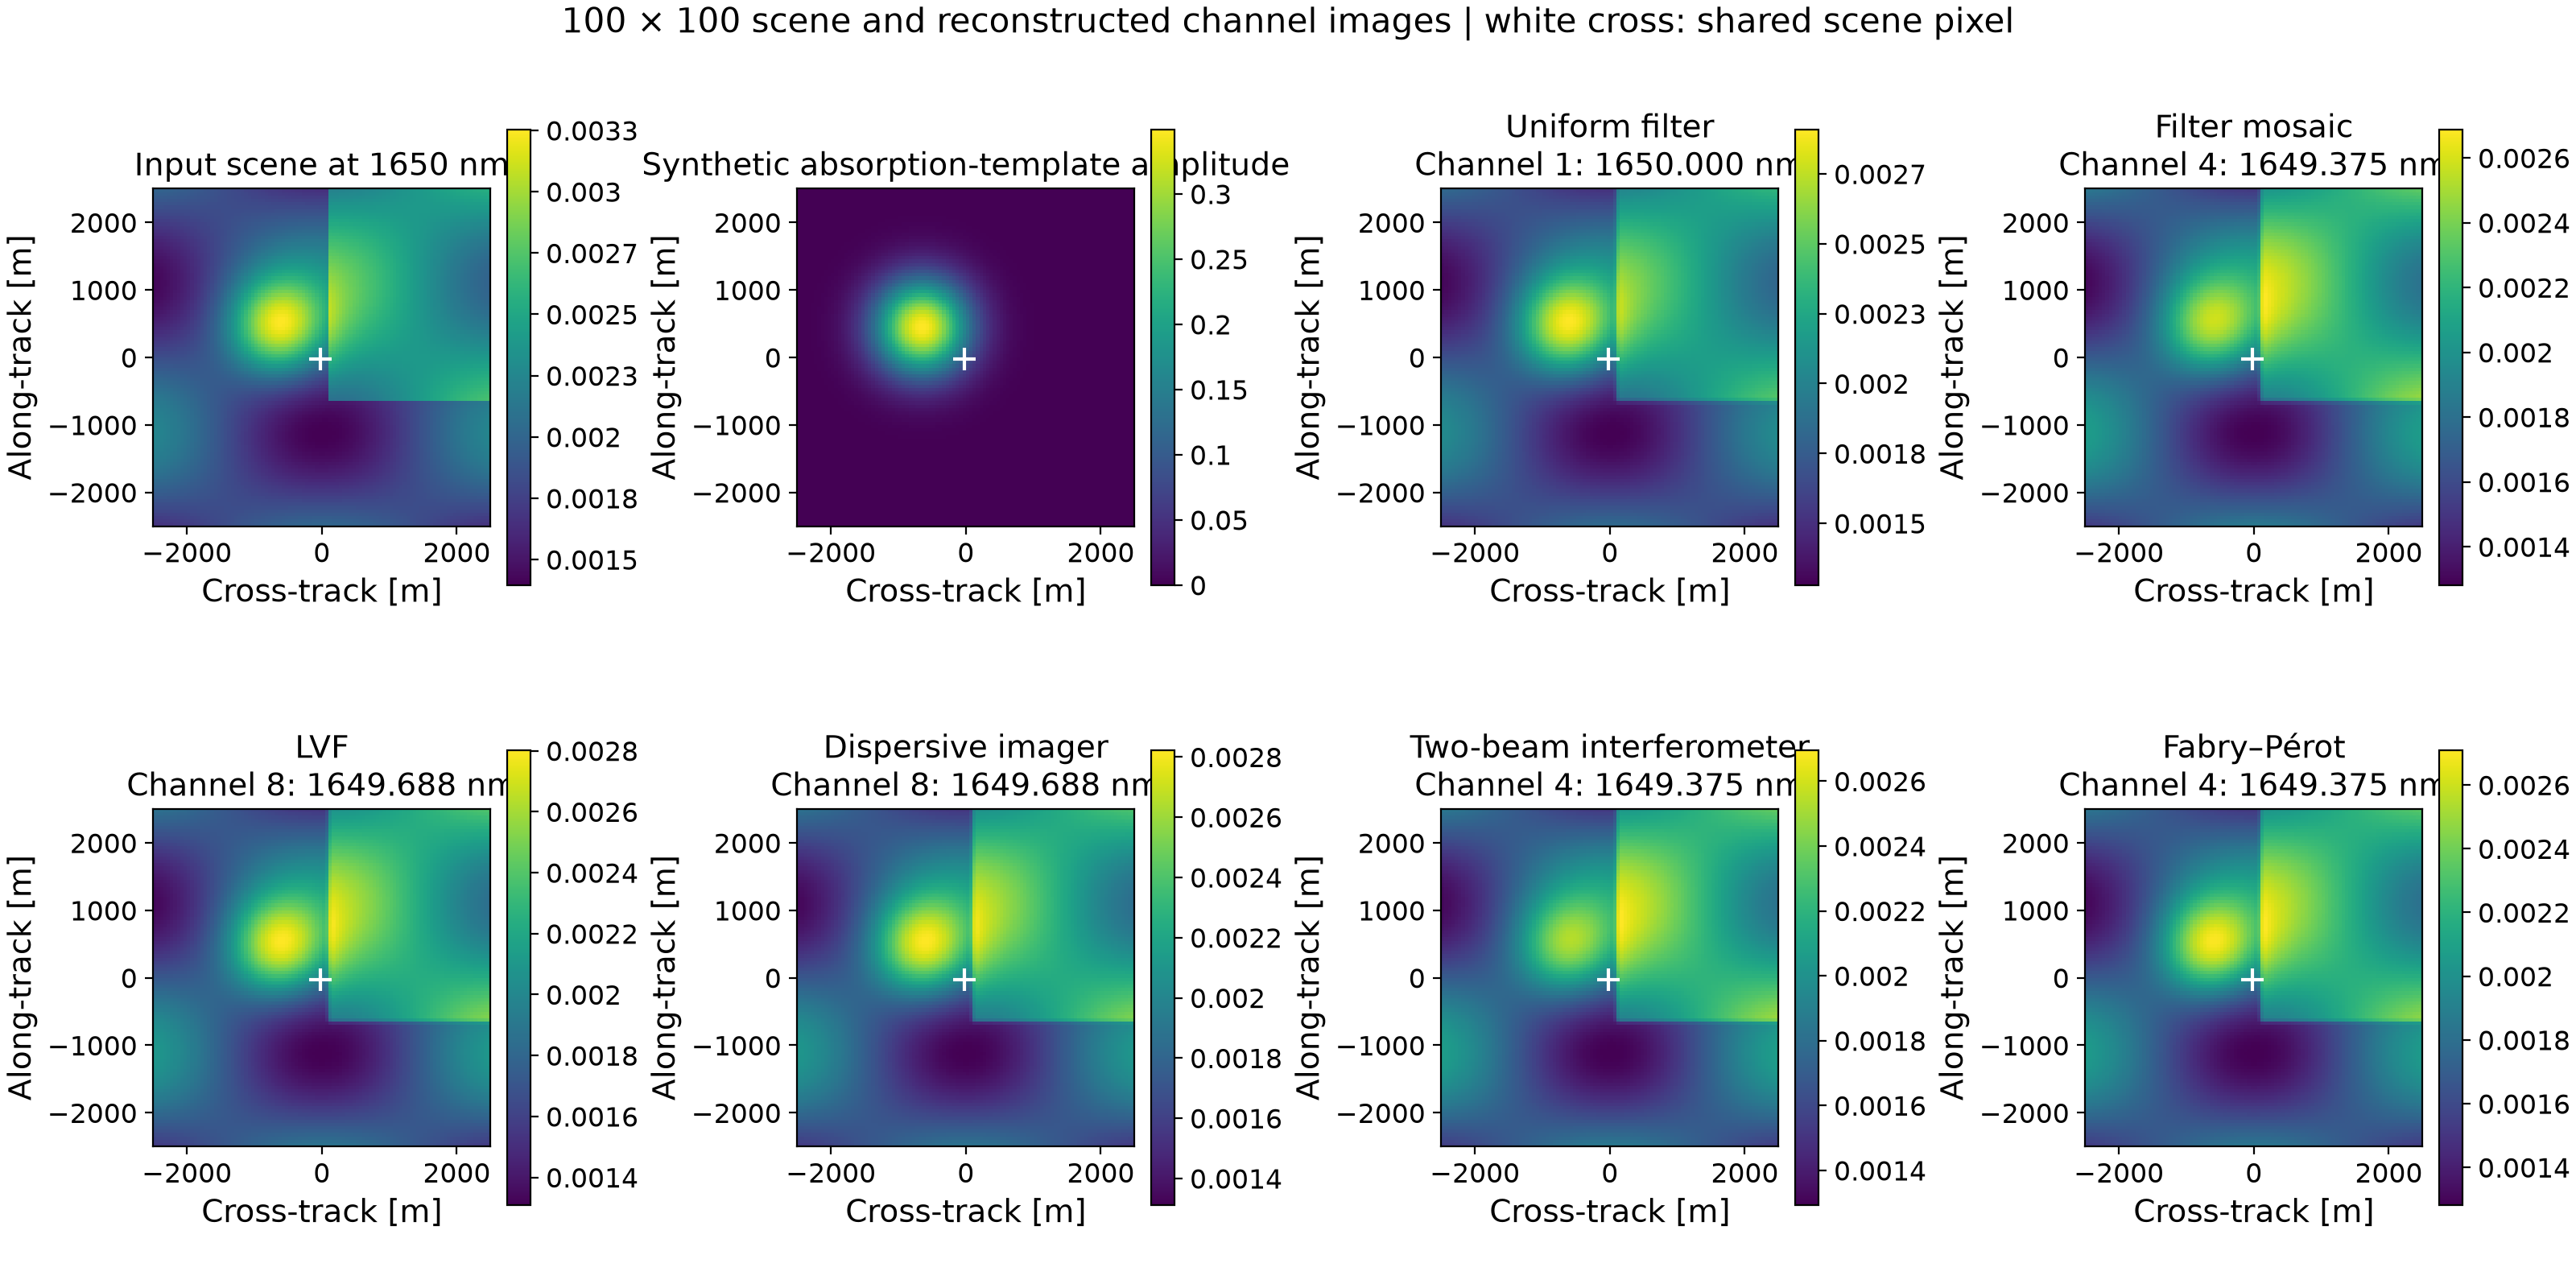

In [5]:
show_scene(points, maps, source_spectra, layouts, results)


## 6. Constant-source and effective spectral responses after K and W

A spatially uniform full-band flat source of **0.001 W m⁻² sr⁻¹ per cm⁻¹** reconstructs to that radiance in every calibrated channel (recorded in `channels.json`). The left panels extend this constant source across 1635–1665 nm and mark the ideal entrance acceptance. The right panels show all channels of **W @ H**, divided by the cm⁻¹ trapezoid weights to give effective response density in **(cm⁻¹)⁻¹**, versus **source wavelength**. Each channel has a unique colour and a legend entry giving its nominal centre. Direct optical families have positive response densities; the interferometric reconstruction has signed densities with positive and negative lobes. The density integrates to unity in wavenumber; its ordinate represents spectral sensitivity. All channels and weights remain in `operators.npz`.

For an arbitrary incident spectrum L, a uniform-scene channel is Σₖ (W H)ᵢₖ Lₖ. The constant-source curves expose bandwidth, finite slit/pixel integration, cavity wings and signed interferometric sidelobes. A diagnostic narrow source of finite width is evaluated by integrating these kernels over its declared interval. Ideal entrance rejection gives zero outside 1645–1655 nm, independently of the inherited atmospheric coverage. These response curves concern the same reconstructed scene-pixel channel, while the source wavelength varies.

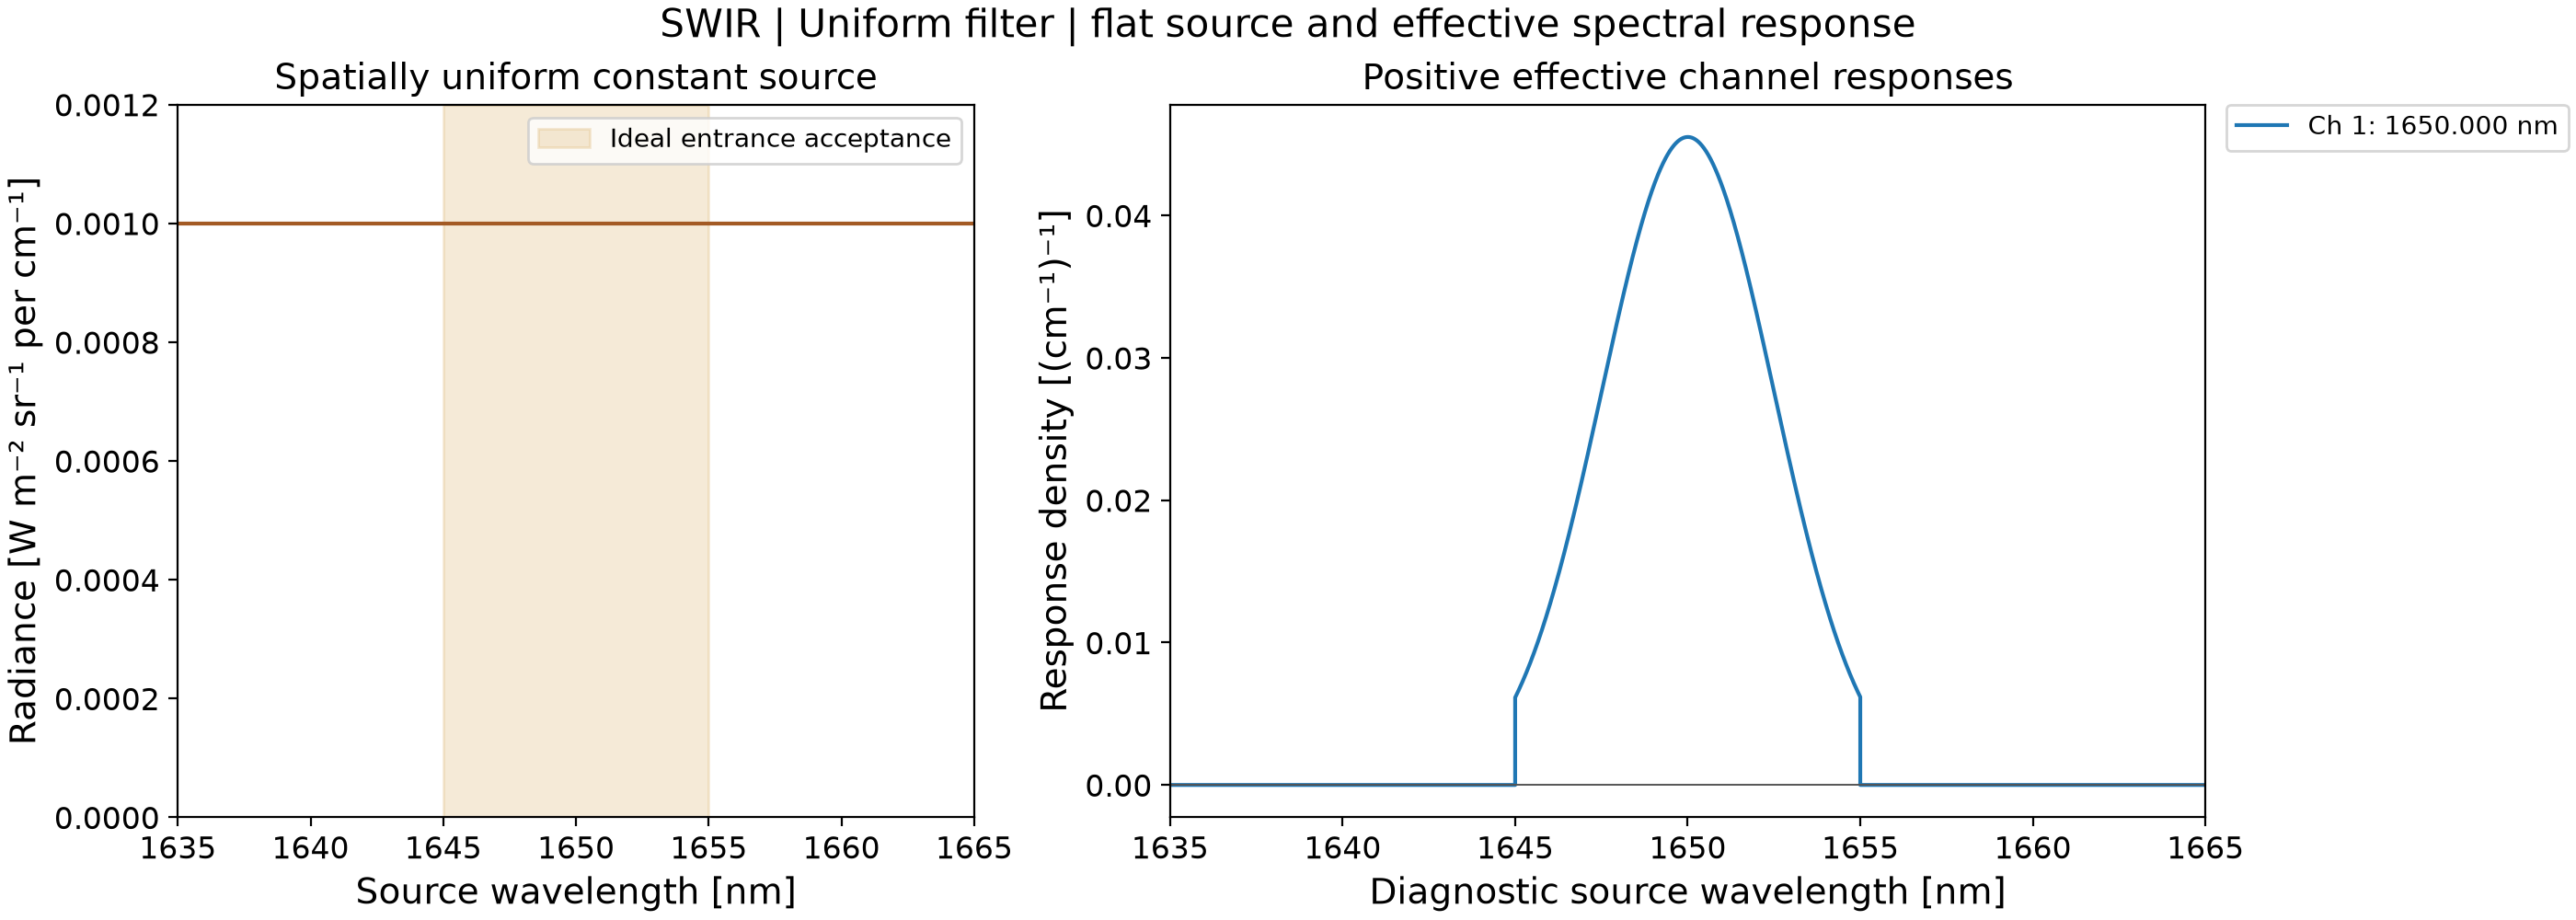

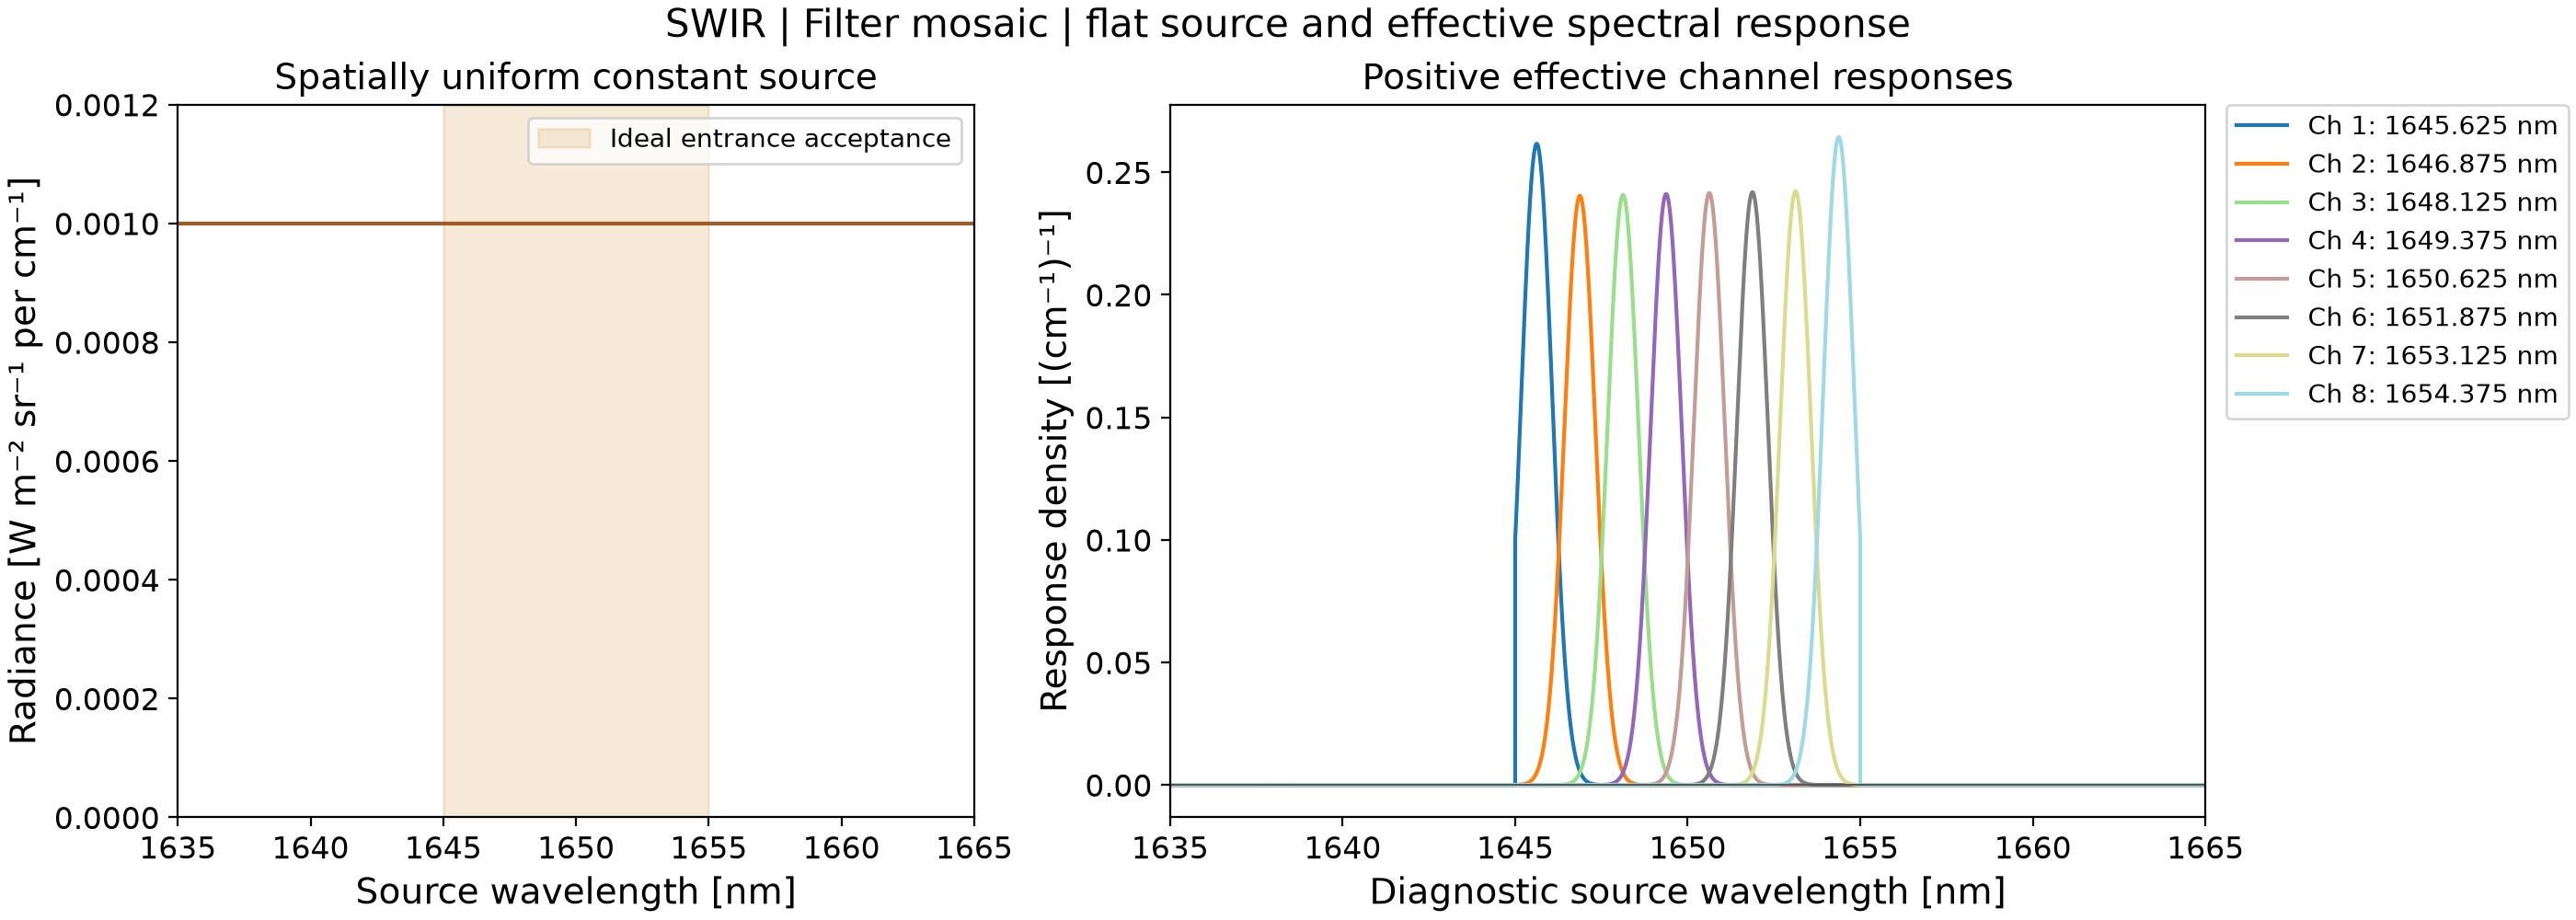

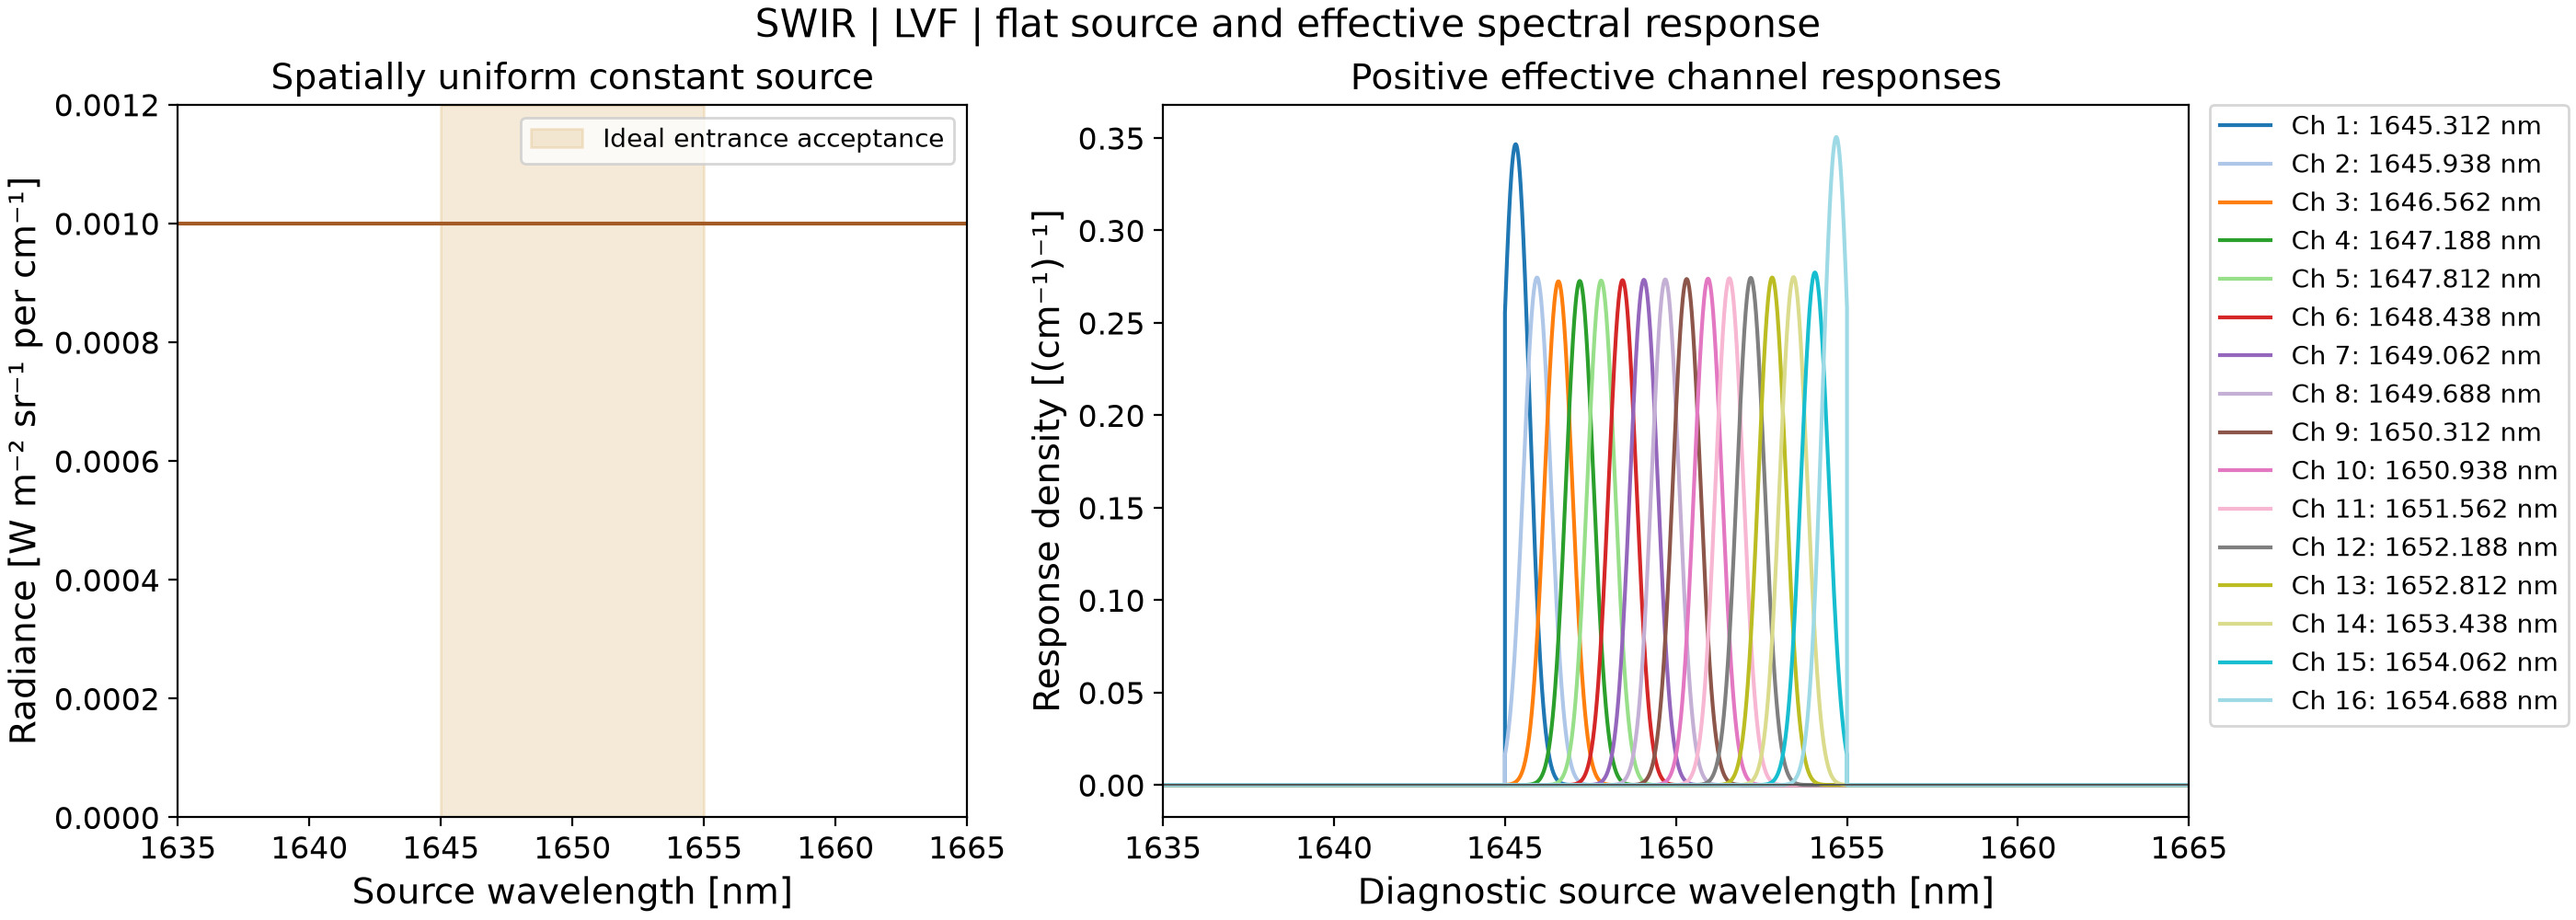

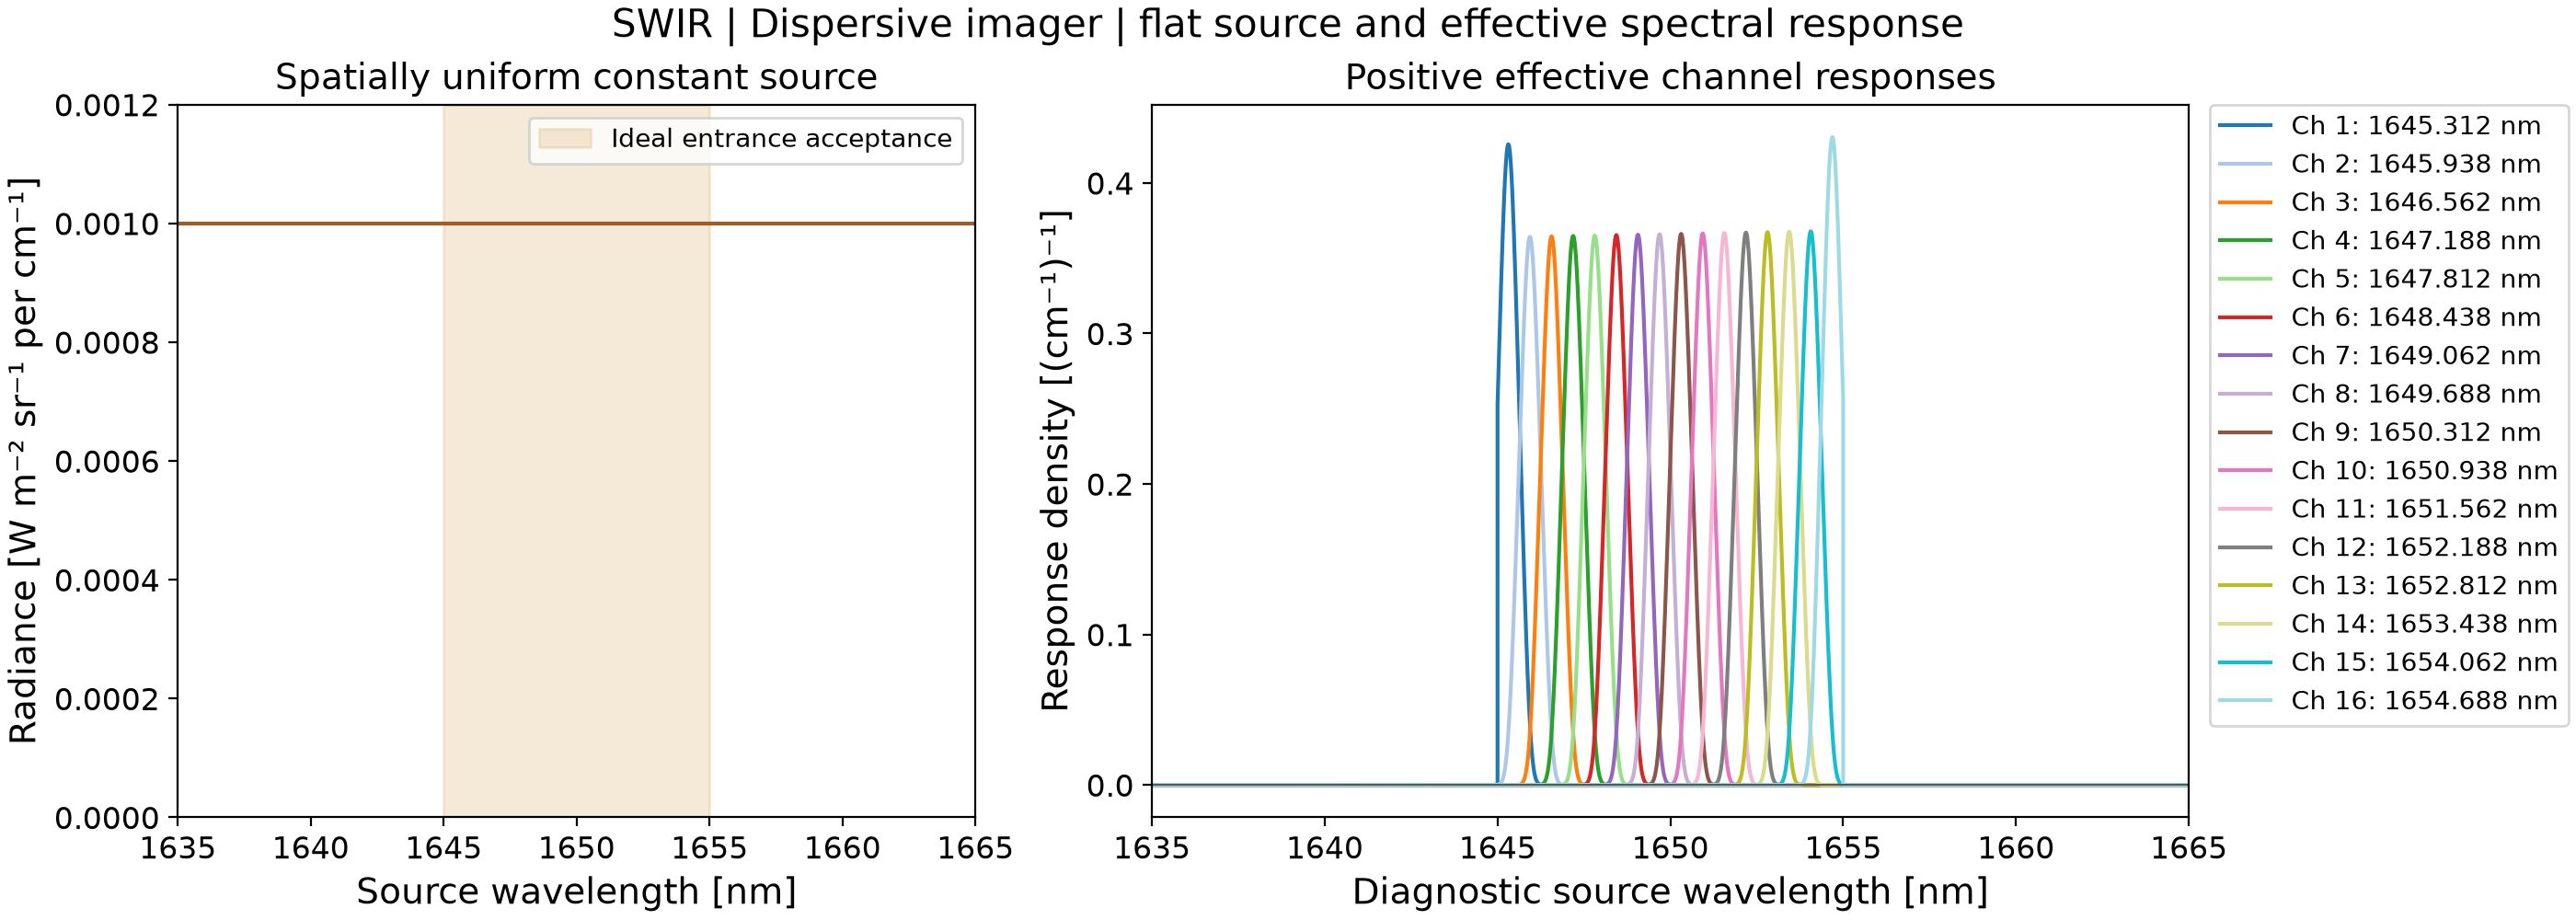

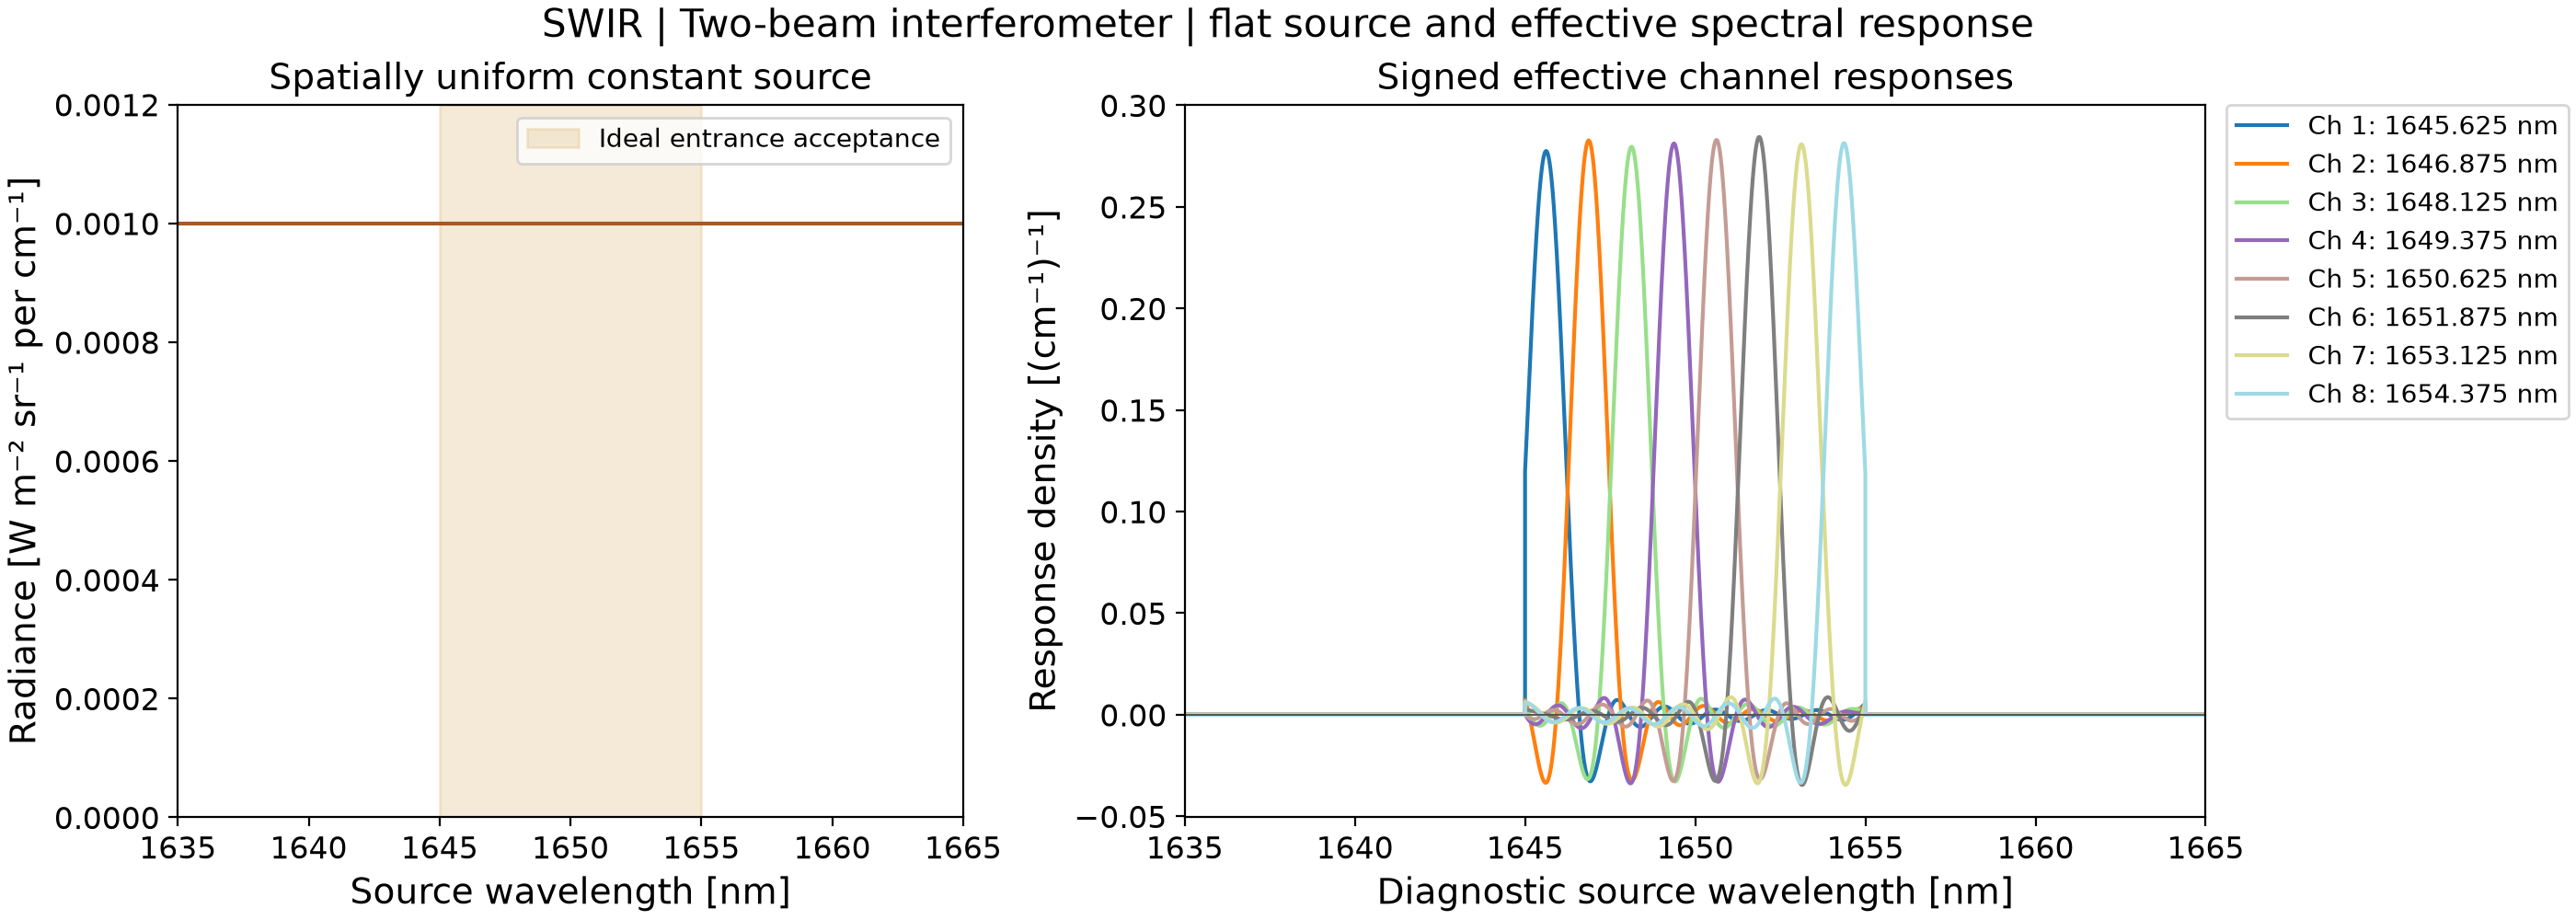

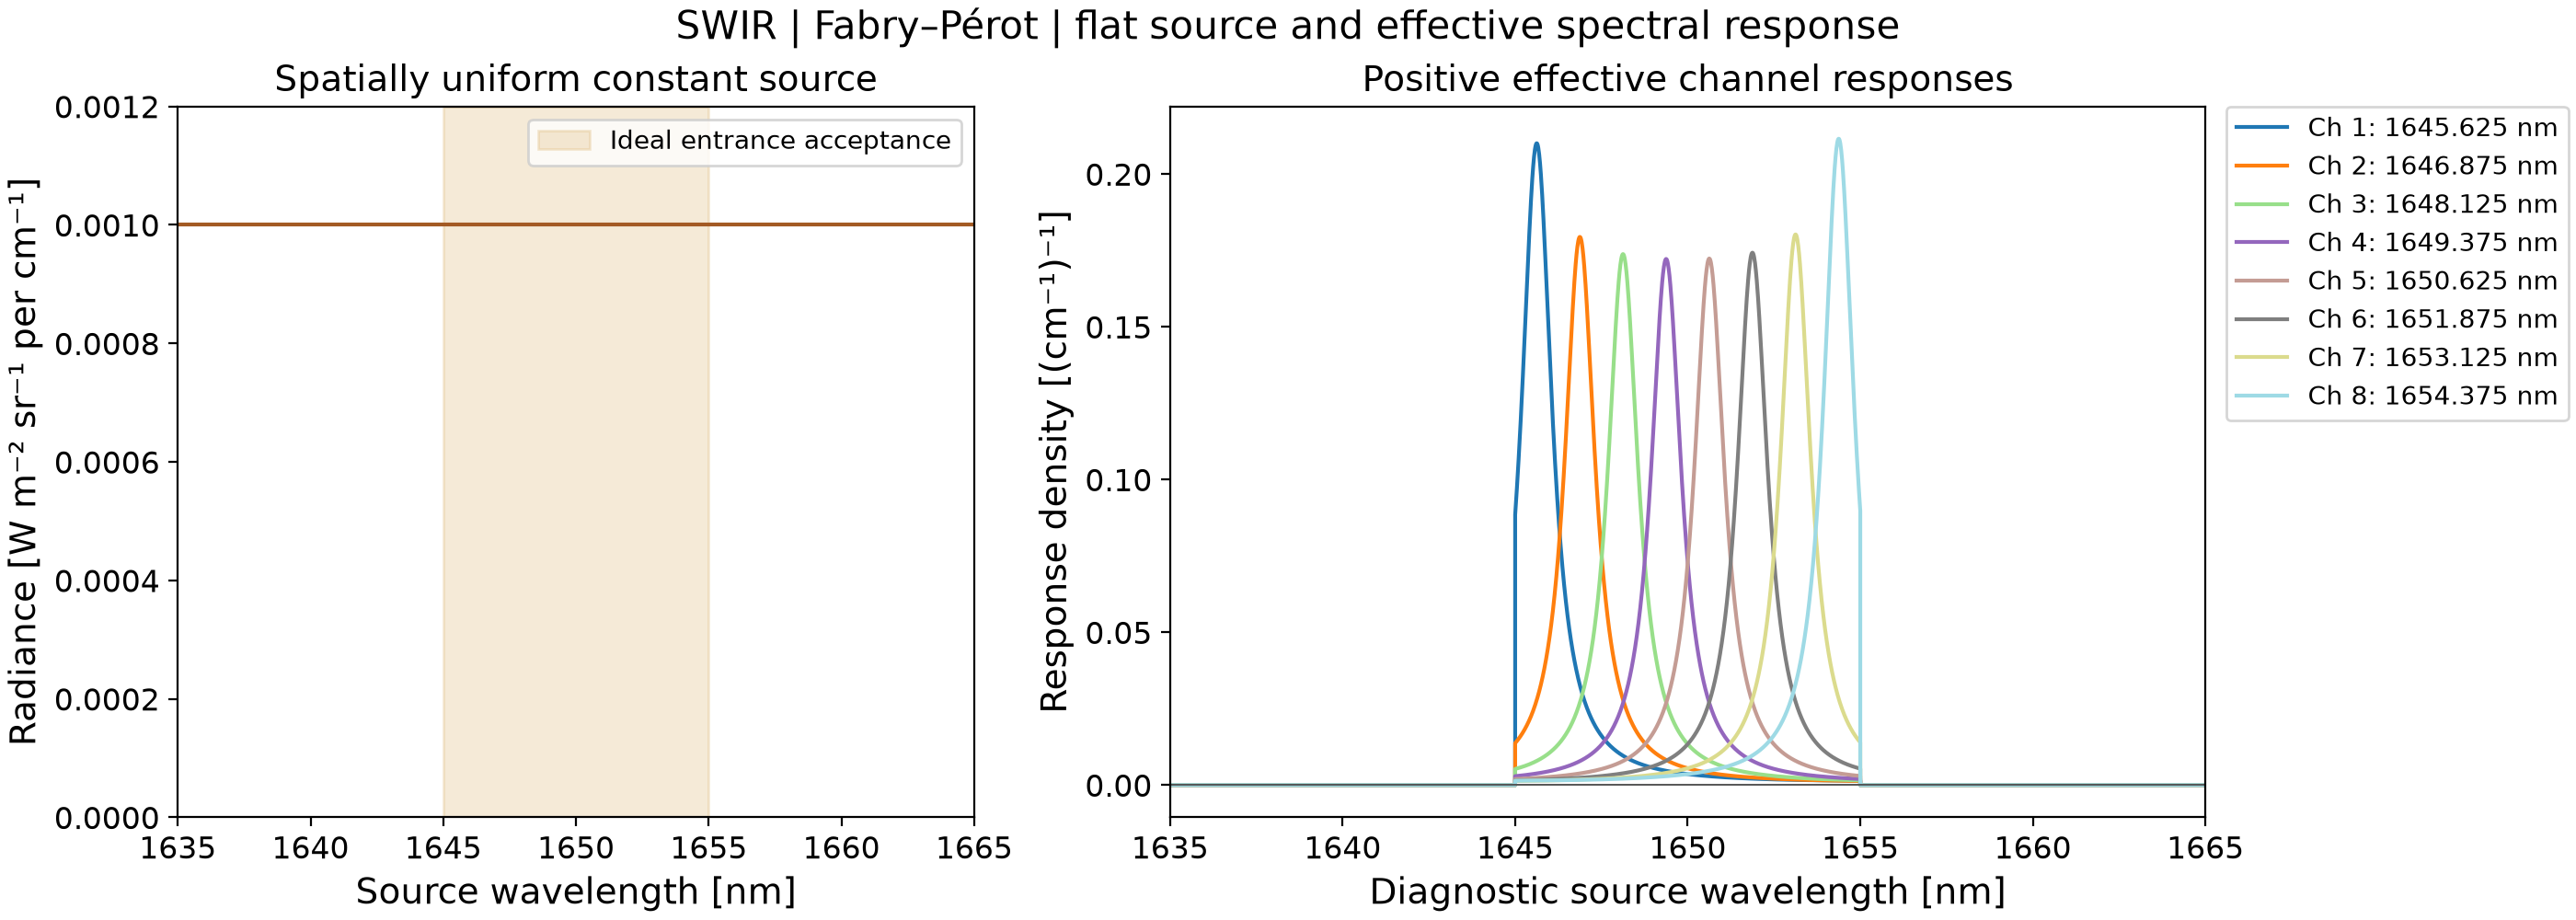

In [6]:
cm_weights = np.r_[np.diff(points)[0], points[2:]-points[:-2], np.diff(points)[-1]] / 2
show_effective_responses(points, cm_weights, settings, layouts, results)


## 7. Full-spectrum atmospheric channel comparison

Each left panel shows the same complete synthetic scene-pixel spectrum, formed from the inherited atmosphere and local surface templates. Each right panel shows the architecture's reconstructed channel means after spatial integration, followed by read-domain digitization and pedestal removal. Channel centres are nominal labels; the effective kernels above define their actual spectral sensitivity. Error bars show one standard deviation propagated from independent shot, dark and read noise at this pixel. The uniform filter supplies one broadband datum; its plotted point represents the entire 1645–1655 nm response. The interferometric output can be signed for spectra outside its finite reconstruction basis.

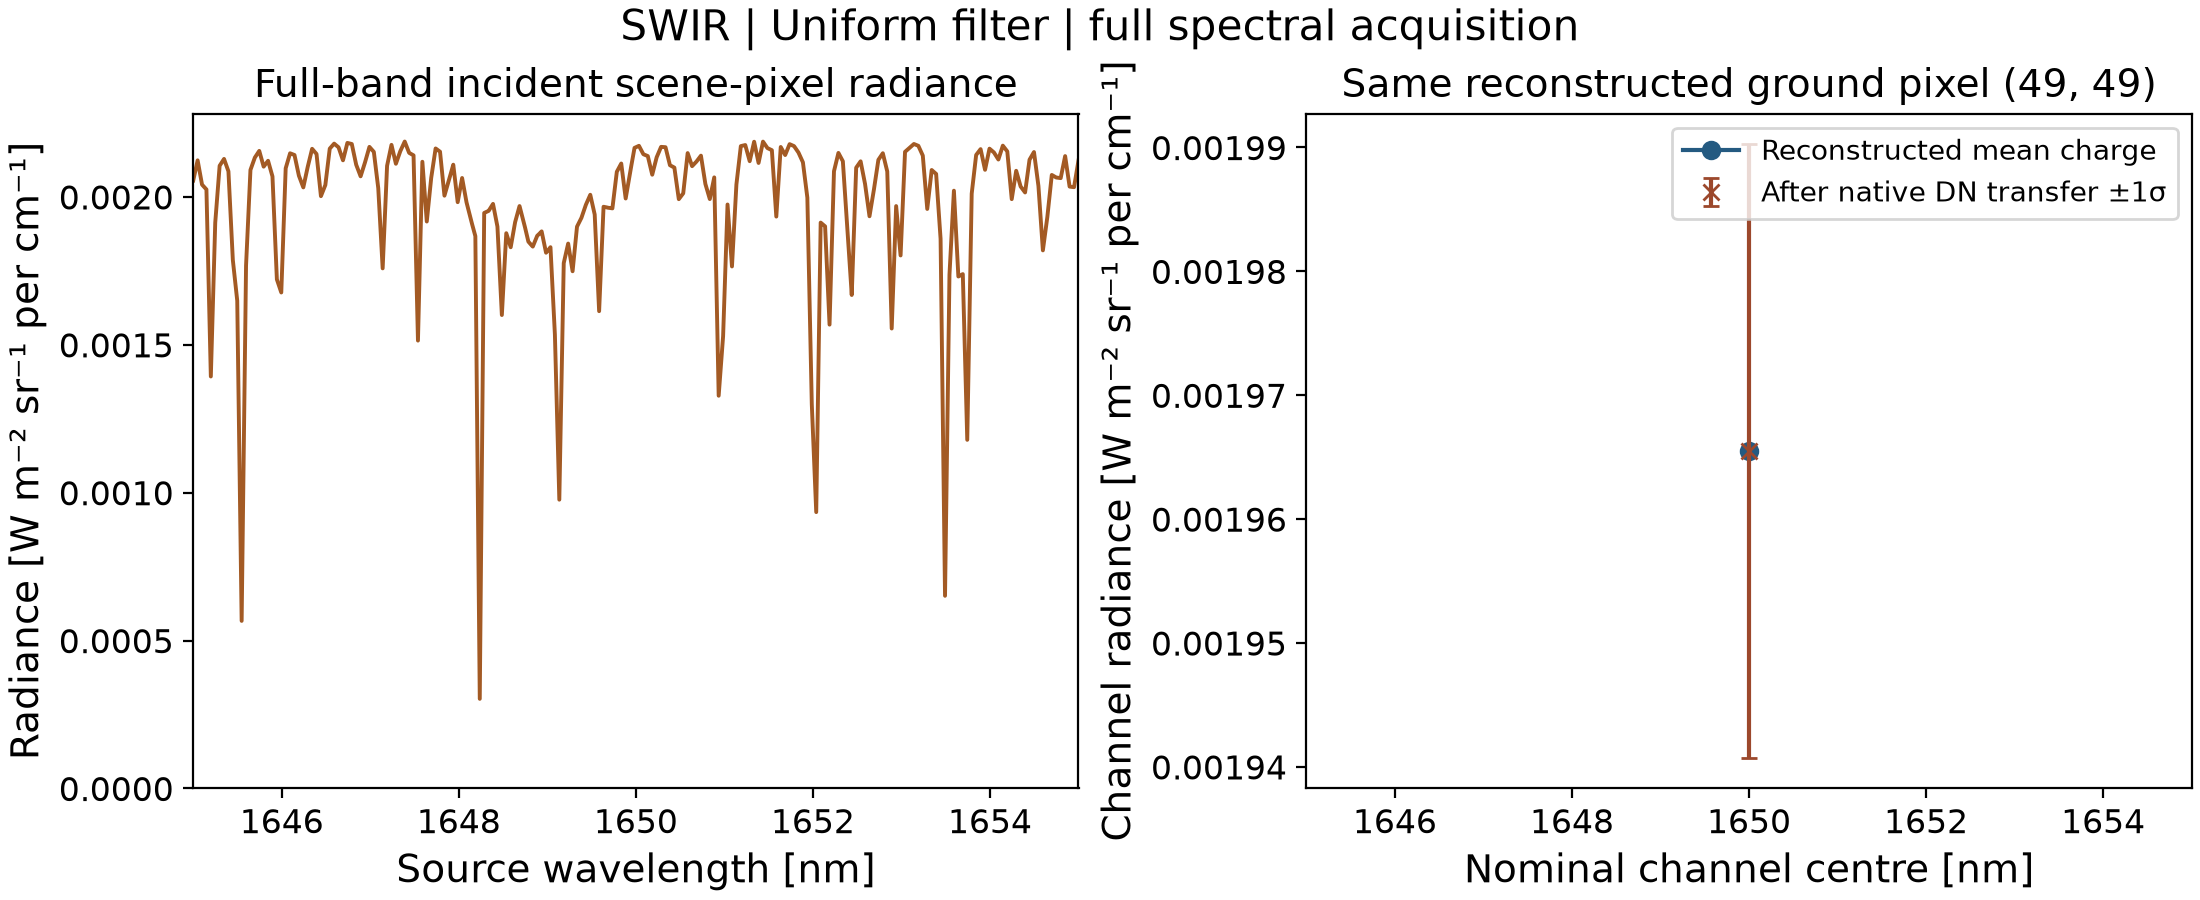

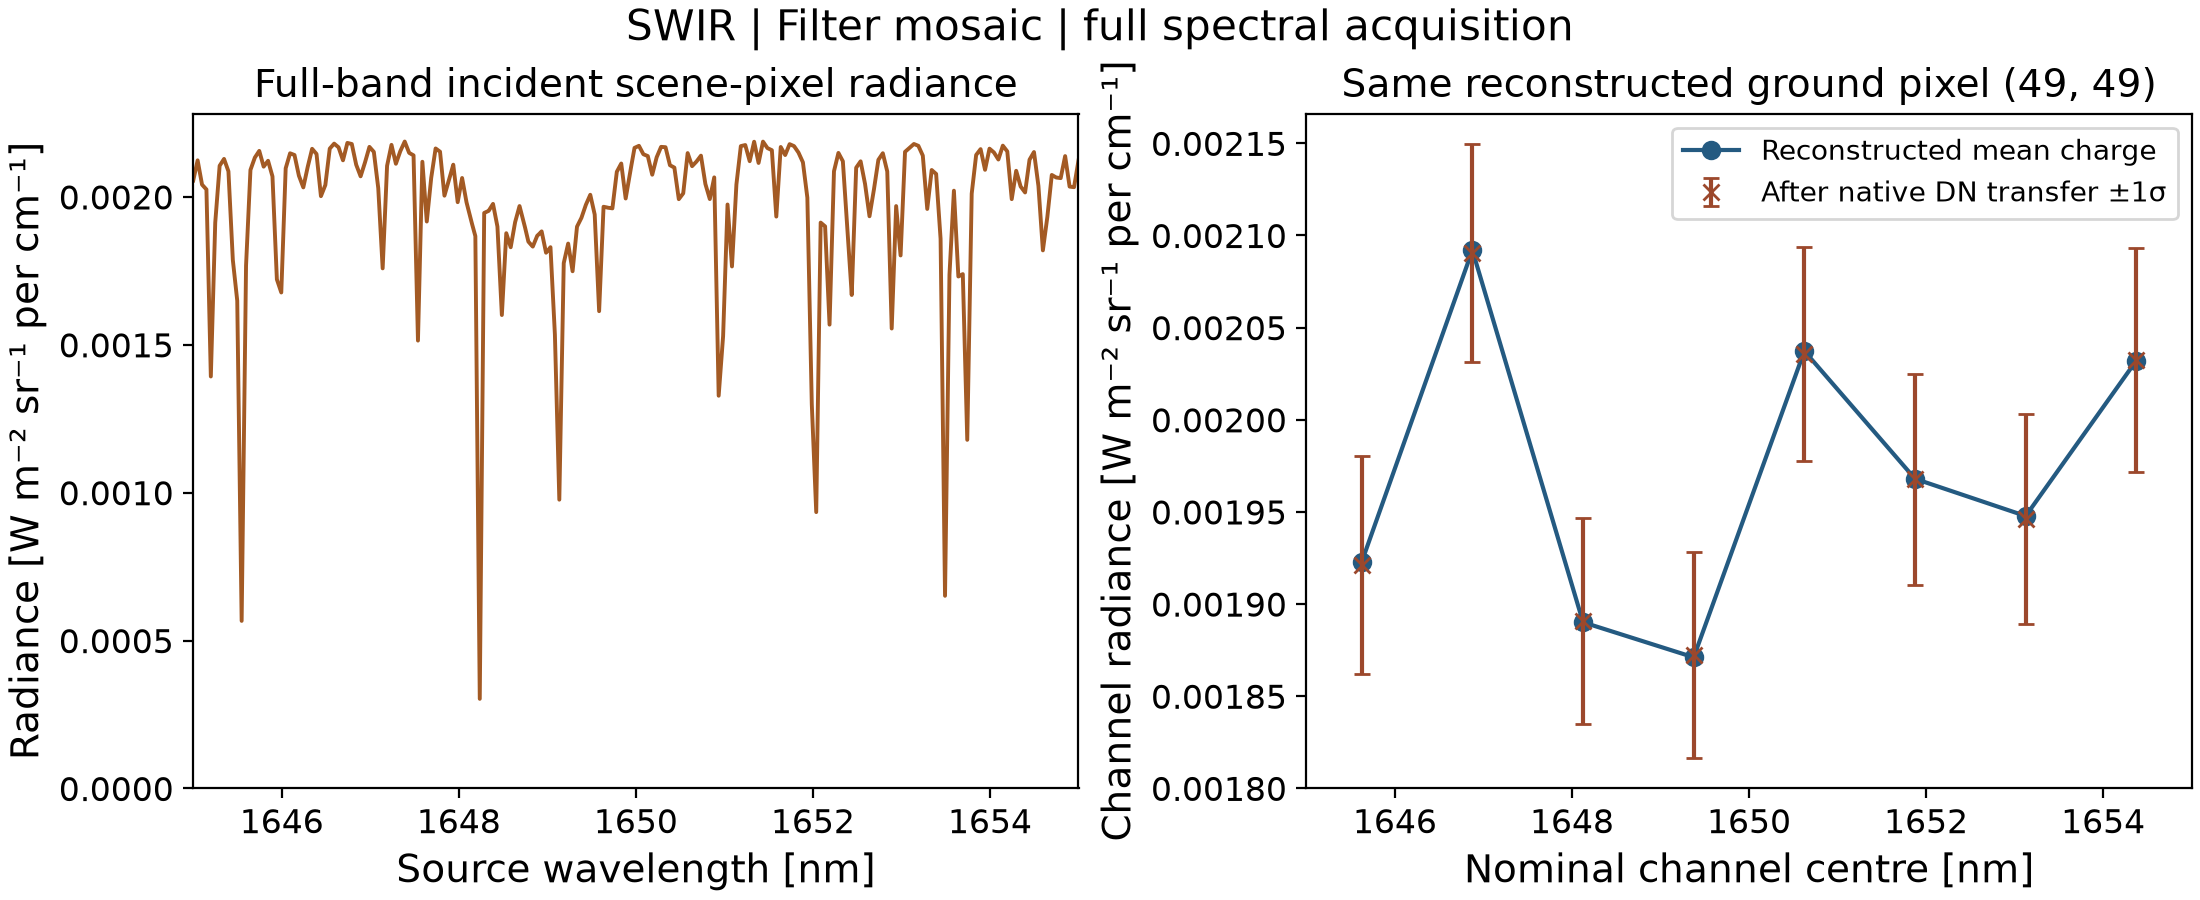

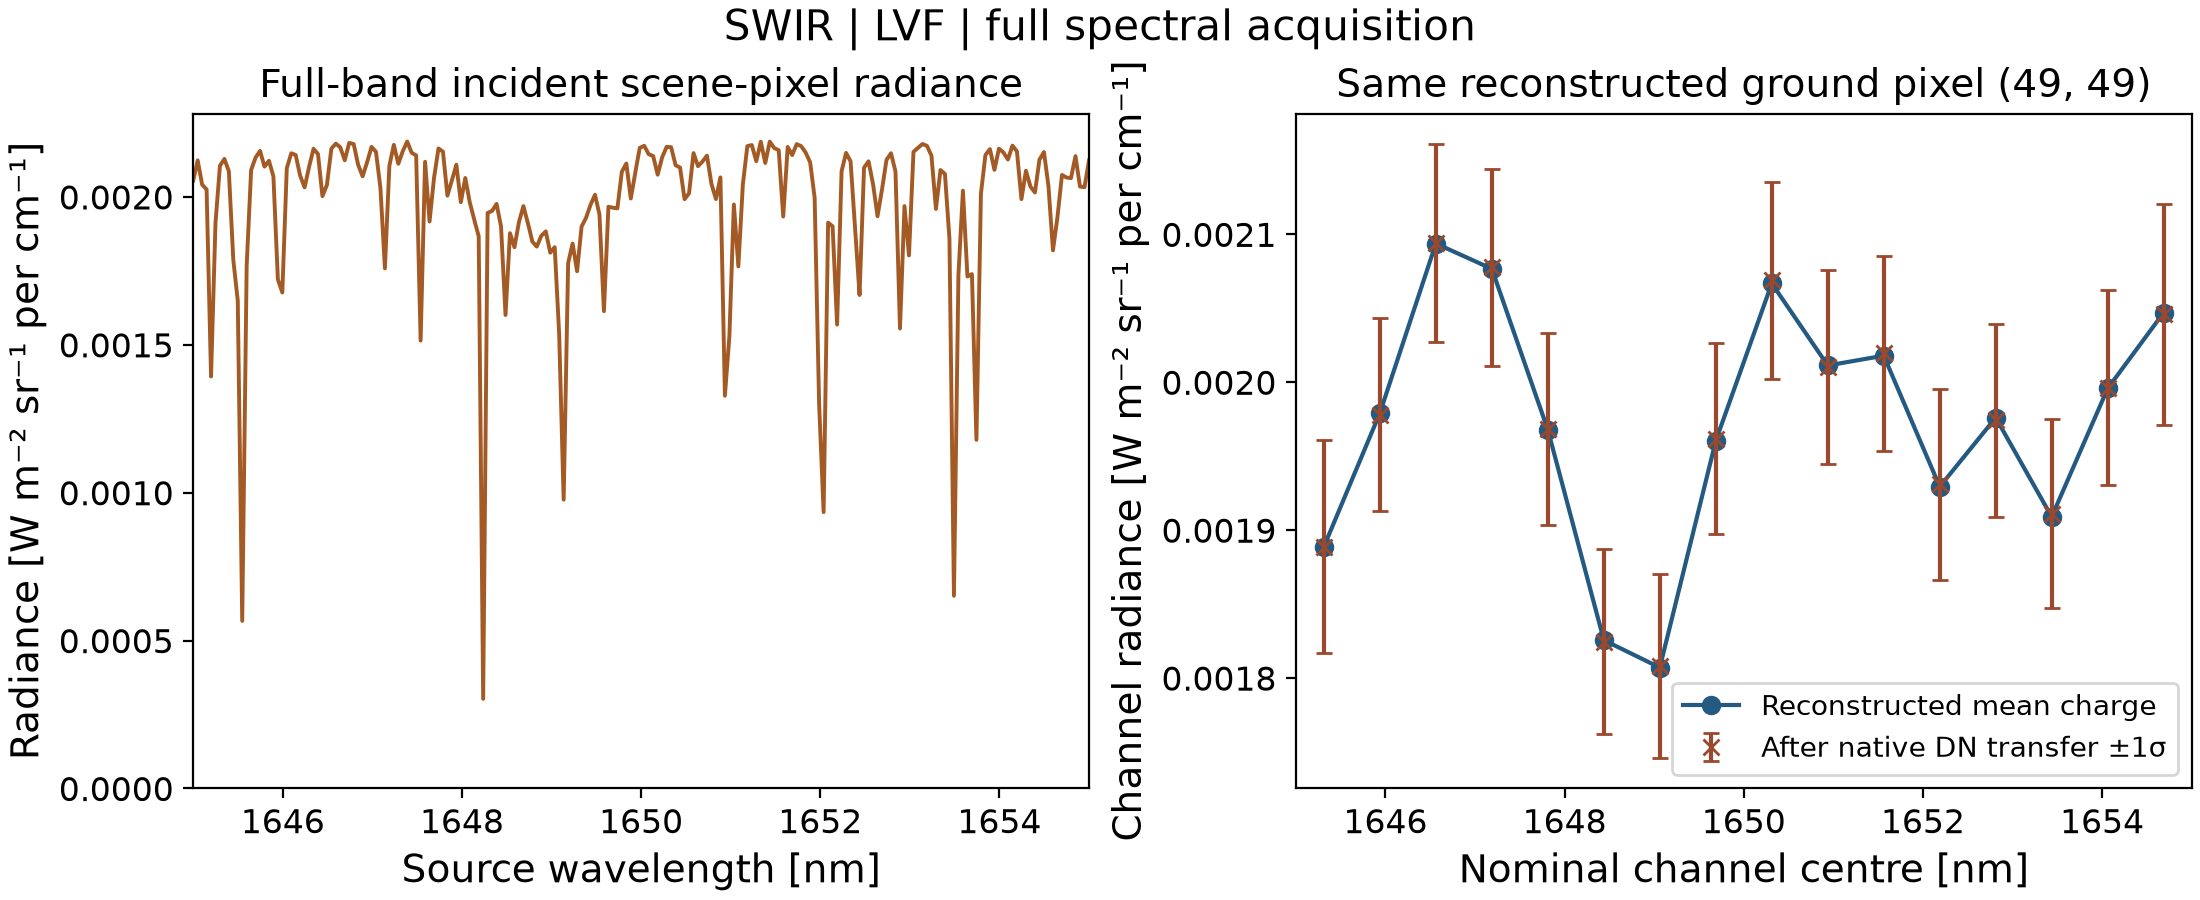

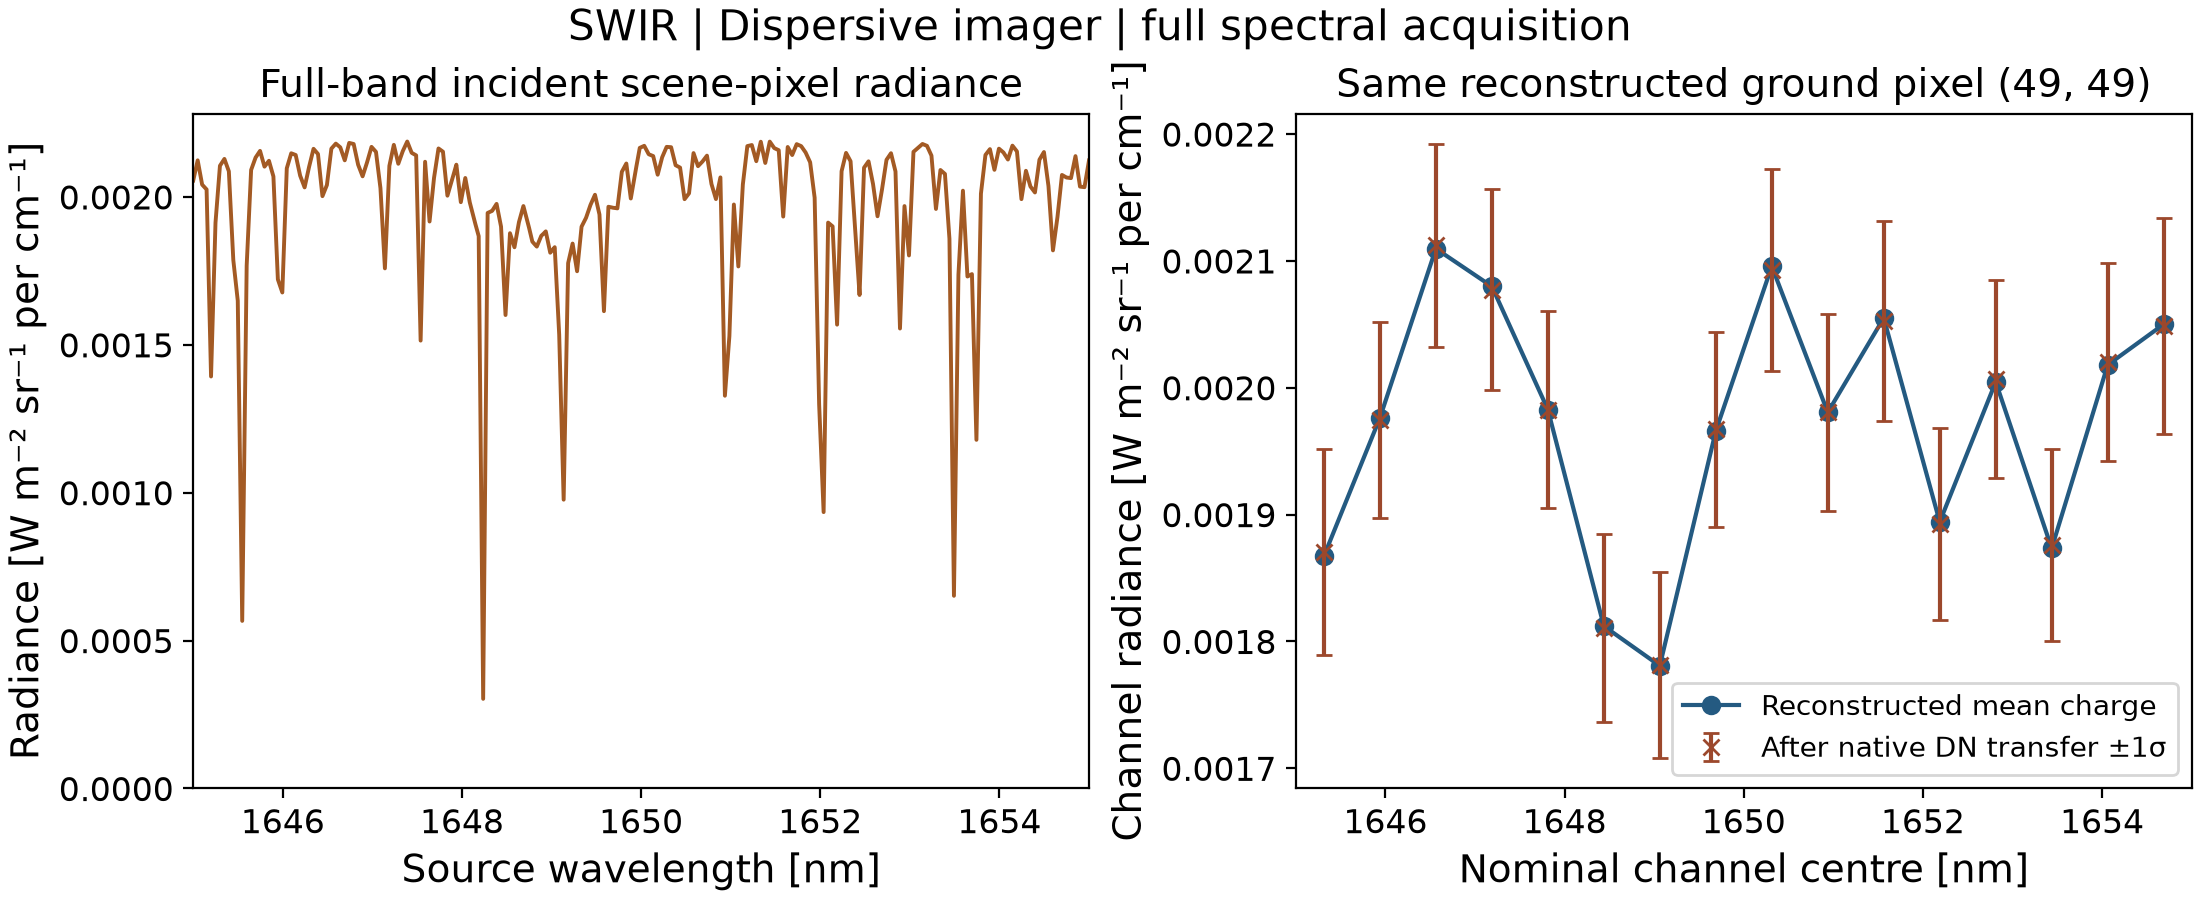

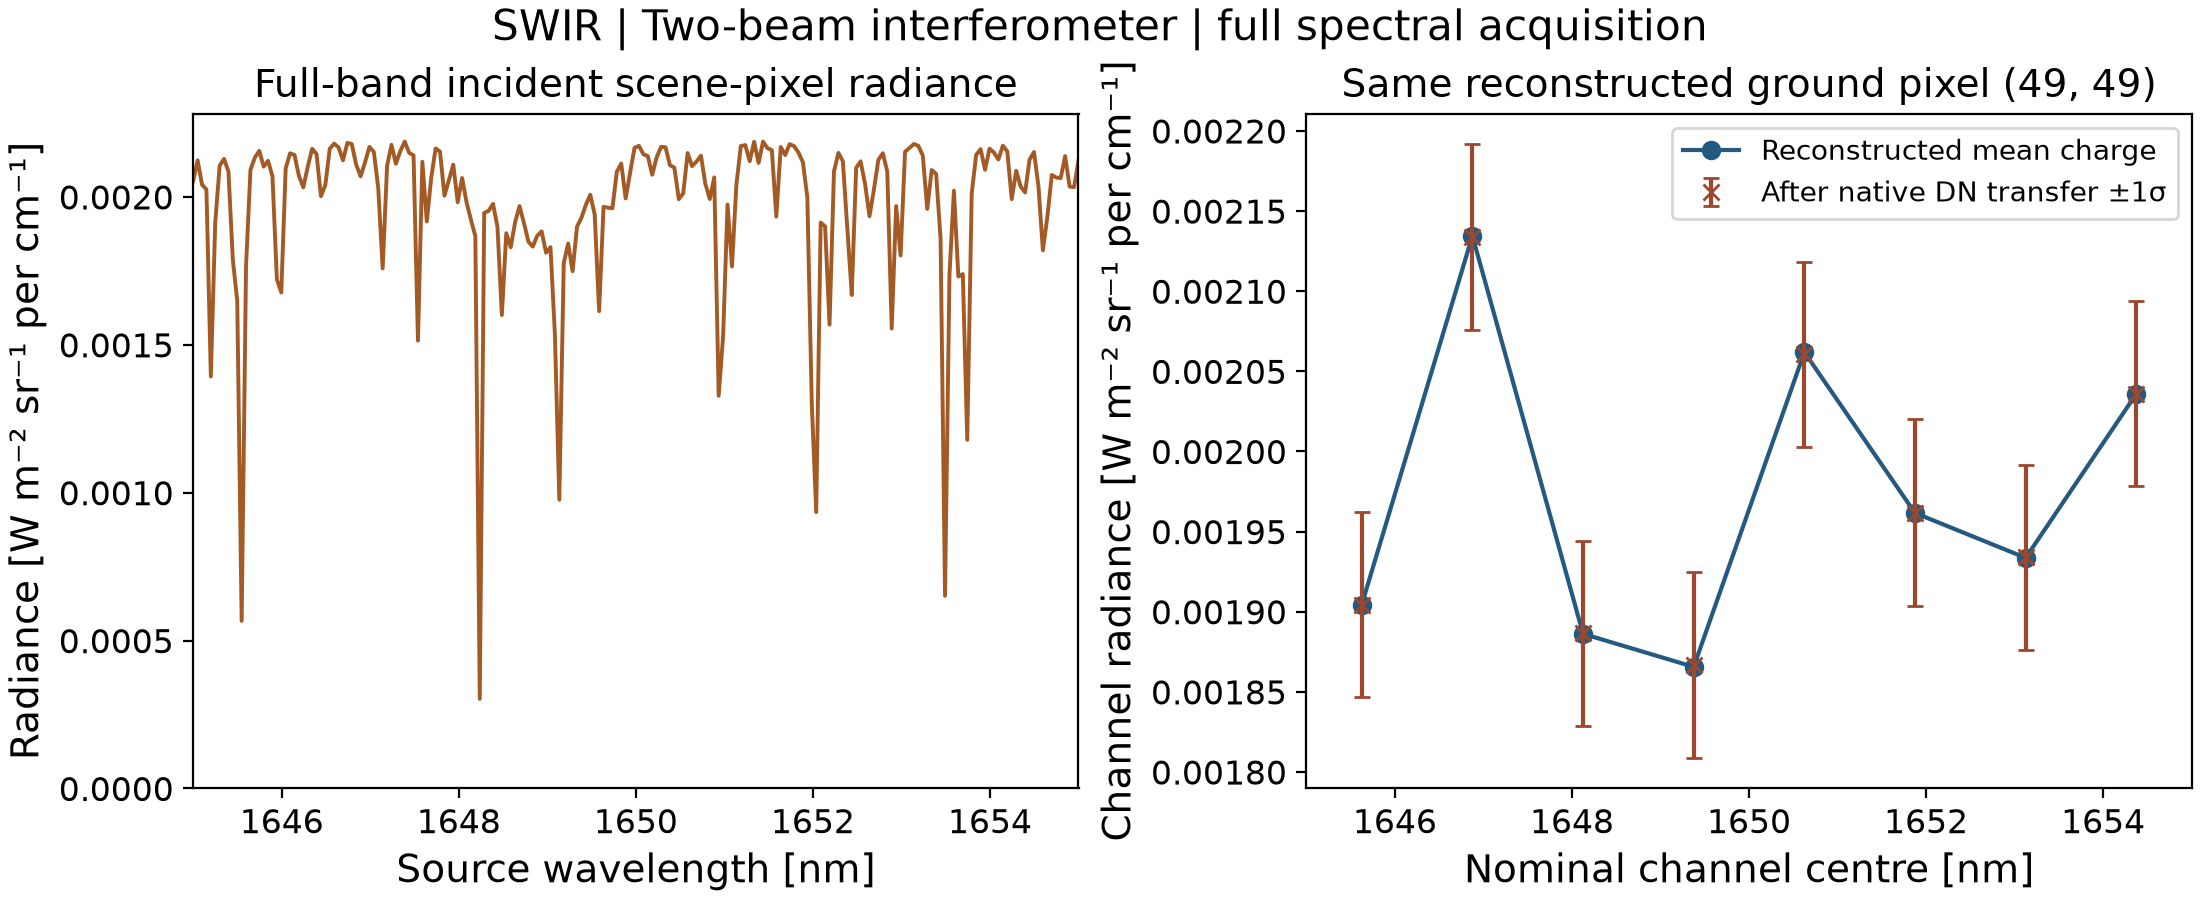

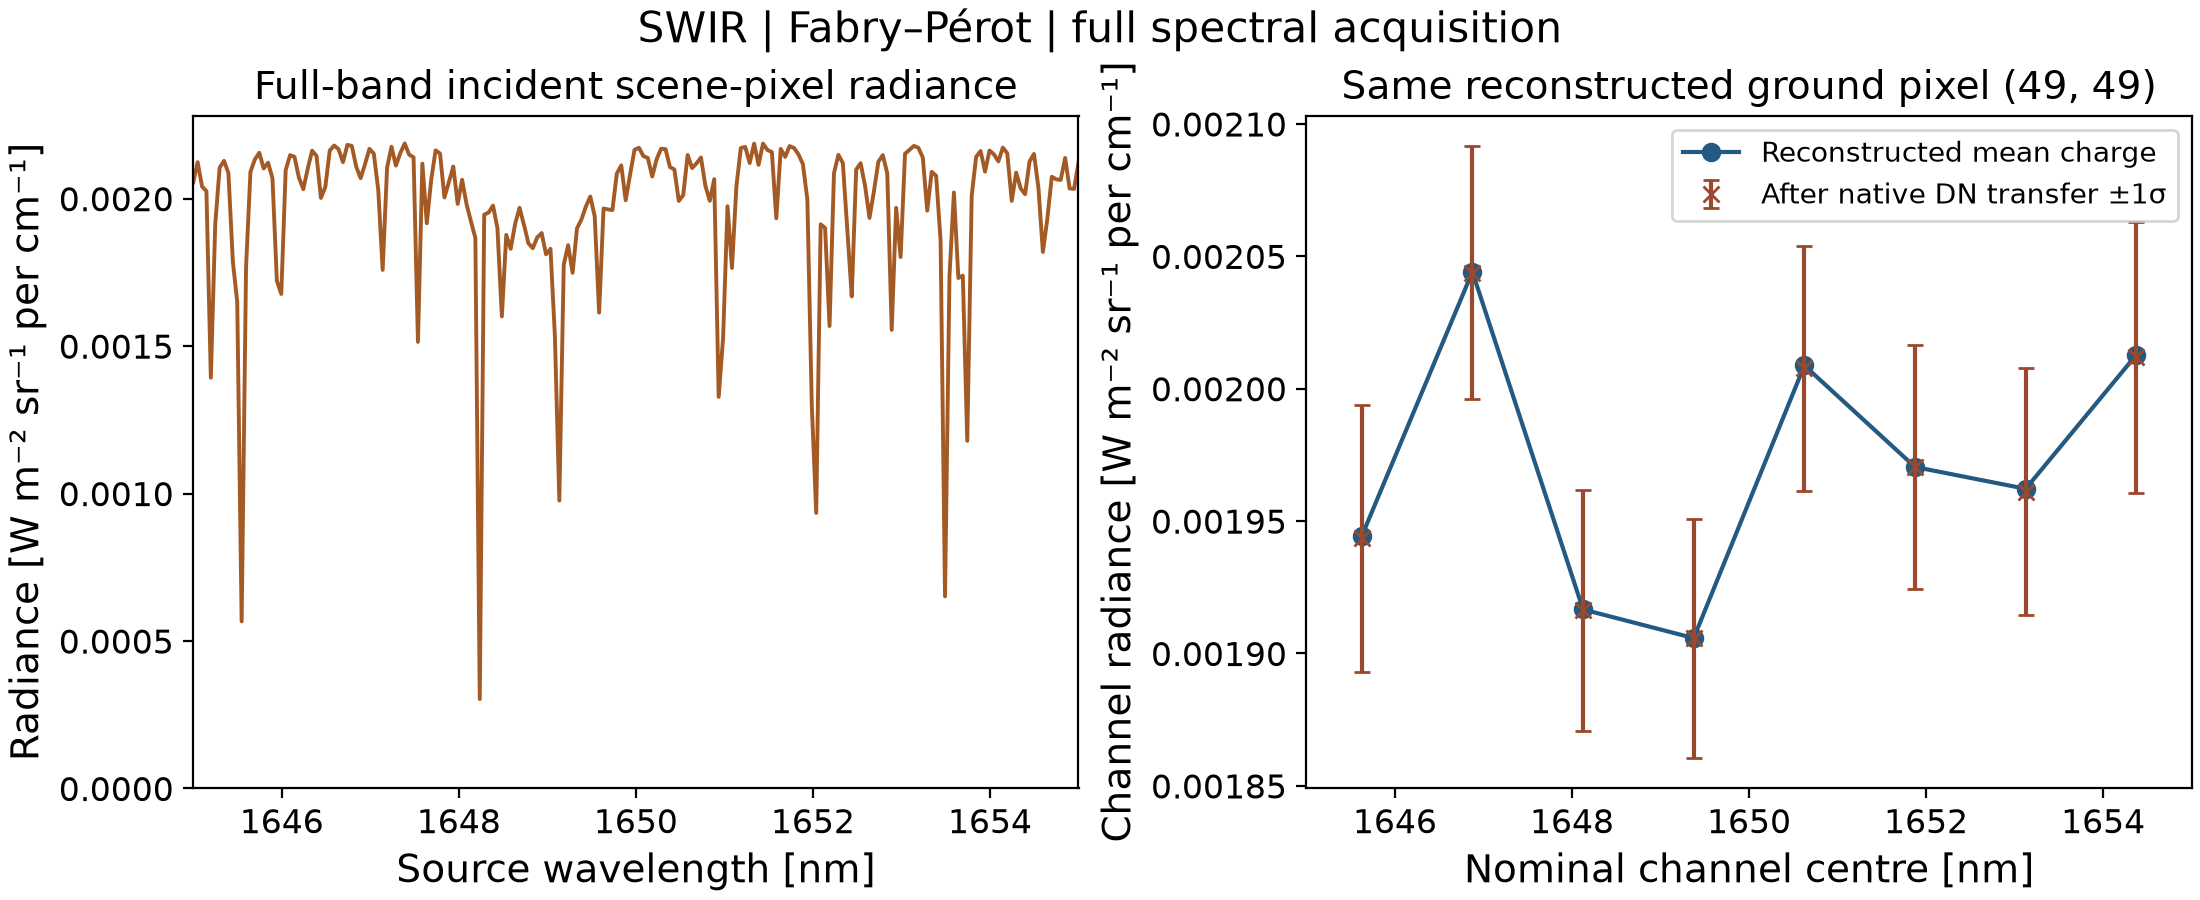

In [7]:
show_atmospheric_channels(points, scene_pixel, layouts, results)


In [8]:
checks = check_acquisition(
    radiance, points, maps, source_spectra, scene_pixel, cm_weights, settings, layouts, results,
)
save_evidence(
    ROOT, OUT, scenario_path=scenario_path, runtime=runtime, settings=settings,
    layouts=layouts, windows=windows, results=results, checks=checks,
    input_hashes=atmospheric['provenance'], preparation_log=preparation_log.getvalue(),
    compute_wall_seconds=time.perf_counter()-started,
)
show_checks(checks, results['Two-beam interferometer'].diagnostics)


| Family | Direct/public relative error | Angular/time refinement | Pixel refinement | Spectral refinement | Edge stencil error |
| --- | ---: | ---: | ---: | ---: | ---: |
| Uniform filter | 4.17e-15 | 5.22e-06 | 0 | 3.74e-07 | 4.06e-15 |
| Filter mosaic | 7.83e-11 | 5.22e-06 | 7.85e-11 | 1.28e-05 | 7.08e-15 |
| LVF | 7.83e-11 | 3.43e-06 | 7.88e-11 | 1.66e-05 | 4.66e-15 |
| Dispersive imager | 1.47e-15 | 0.000147 | 0 | 2.74e-05 | 2.65e-15 |
| Two-beam interferometer | 3.74e-15 | 5.22e-06 | 0 | 2.6e-06 | 3.74e-15 |
| Fabry–Pérot | 3.4e-15 | 5.22e-06 | 0 | 6.62e-06 | 4.48e-15 |

Interferometric eight-bin rank **8**, condition **1.32**, basis closure **7.31e-16**. The supplied high-resolution scene spectrum differs from its ideal bin averages by **1.402%** after W @ H. The effective kernels describe this finite-basis sensitivity. Local numerical checks use the declared **0.3%** integration-sensitivity threshold and representative samples; the atmospheric 201-point interpolation remains the spectral source model.

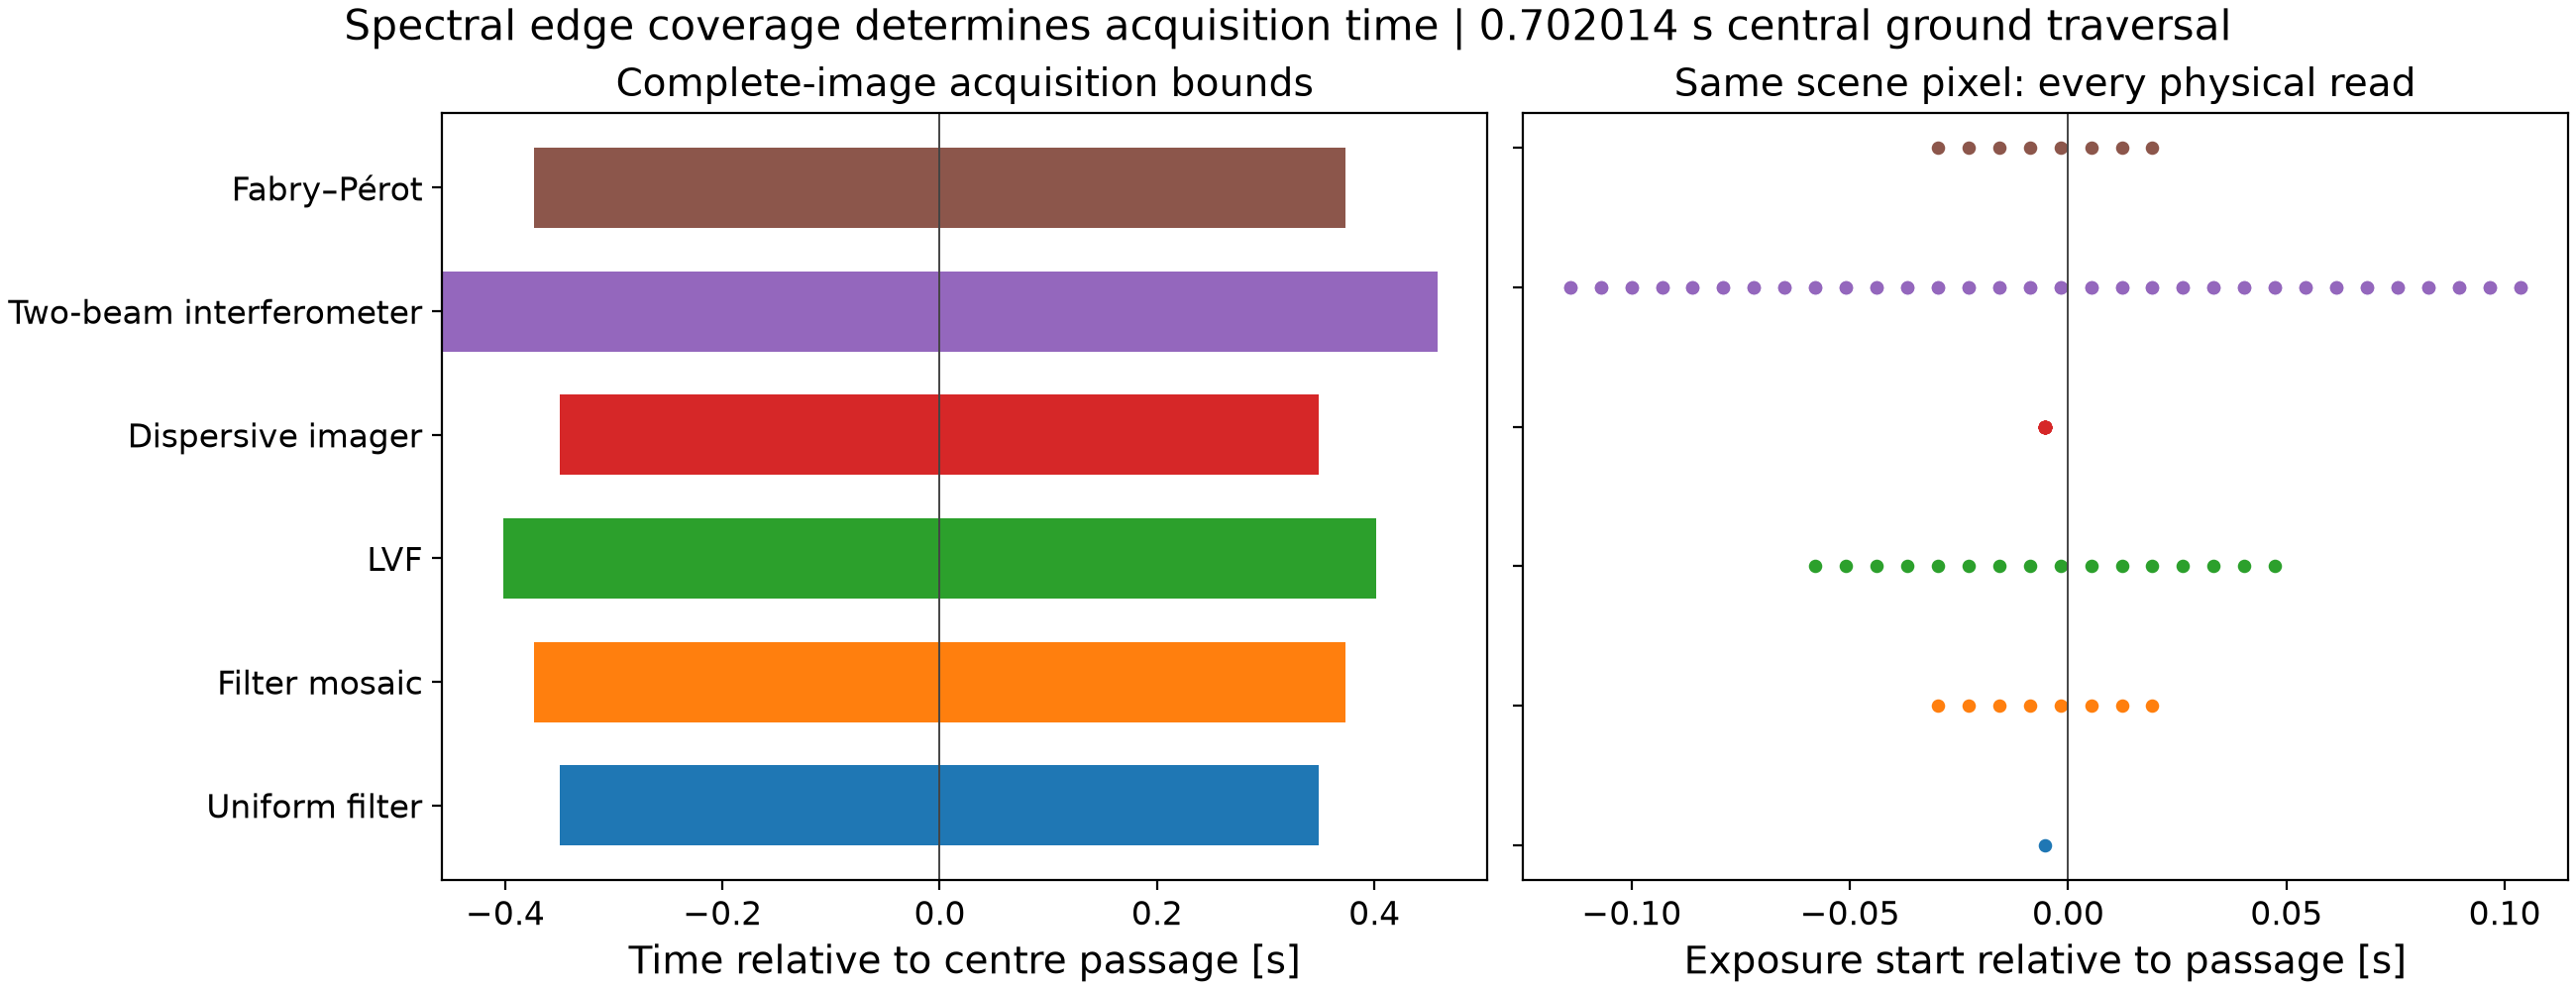

In [9]:
show_acquisition_timing(windows)


## Reproducibility and scientific scope

Run `devbox run -- just execute-instrument-responses` from the repository root with enriched local inputs provisioned as described in `notebooks/README.md`. The canonical notebook retains tables and fourteen embedded figures: scene evidence, six constant-source response pairs, six atmospheric pairs and acquisition timing. Retina PNG exports, `operators.npz`, `scene-images.npz`, `channels.json` and `evidence.json` are saved in `outputs/instrument-responses/`. The operator archive names the families in order and retains K, H, W, W @ H, the source wavenumbers and all target/read exposure bounds. Scene archives retain native electrons/DN and calibrated channels before/after deterministic digitization. The receipt records source/input hashes, imported free-threaded runtime, affinity/thread limits, settings and bounded checks. `devbox run -- just replay-instrument-response` executes the current instrument cells on locally generated spectral-scene archives, writes separate replay arrays and compares them with this clone's instrument execution. The offline replay receipt records executed cell hashes and API call counts; saved notebook displays, execution counts and metadata retain their original atmospheric-run provenance.

The comparison qualifies software composition and local numerical agreement for these illustrative models. It uses a static synthetic scene, inherited atmospheric profile, ideal entrance blocking, normal-incidence/telecentric spectral laws, constant-height/speed paraxial geometry and independent read noise. Absolute Toulouse geolocation, curved-Earth/attitude variation, field-angle corrections, measured instrument response, atmospheric spectral convergence, retrieval performance and actual hardware feasibility each require dedicated evidence. The 50 m value describes reconstructed sampling; the integrated spatial response sets the effective resolution. The interferometer's eight-bin prior and signed high-resolution sidelobes define its spectral interpretation.